# Final Project: CCDB June-2026 Report

## Set Up

Libraries, settings, the data file's path, and `check()`, the helper that prints a PASS/FAIL line for every check in the notebook.

In [1]:
# --- Setup ---------------------------------------------------------------
# Libraries, settings, the data path and the check() helper used across the notebook.
import hashlib
import json
import os
import re
import sys
import textwrap
import time
from collections import Counter, defaultdict
from pathlib import Path

import anthropic
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import openpyxl
import pandas as pd
import pypdf
from pypdf import PdfReader
import sklearn
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)

# Paths resolve from the project root, so the notebook runs on either partner's machine
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_DIR / "data" / "raw" / "CCDB_Export_19_June_2026.zip"
# The CFPB complaint form's Product / Sub-product / Issue options (August 2023, the latest major revision)
FORM_PATH = PROJECT_DIR / "reference" / "cfpb_consumer_complaint_form_product_issue_options_August_2023_FINAL.pdf"


def check(name, passed, detail=""):
    """Print one PASS/FAIL line for a named check; returns whether it passed."""
    print(f"{'PASS' if passed else 'FAIL'}  {name}  {detail}")
    return passed


print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__, "| pypdf:", pypdf.__version__,
      "| scikit-learn:", sklearn.__version__, "| anthropic:", anthropic.__version__, "| openpyxl:", openpyxl.__version__)
assert DATA_PATH.exists(), f"Data file not found: {DATA_PATH}"
assert FORM_PATH.exists(), f"Form file not found: {FORM_PATH}"

Python: 3.12.10
pandas: 3.0.5 | numpy: 2.5.3 | matplotlib: 3.11.1 | pypdf: 6.21.3 | scikit-learn: 1.9.0 | anthropic: 2.3.0 | openpyxl: 3.1.5


## Load Data

The CFPB Consumer Complaint Database export of complaints received in June 2026 (source and download steps in the project `README.md`, under Data). Every column is read as text, so types change only in Clean.

In [2]:
# --- Load data -----------------------------------------------------------
# Fingerprint of the June 2026 export, recorded when we first profiled it (2026-10-24).
# A different value means the file is not the one we profiled, so stop before reading it.
EXPECTED_SHA256 = "3021c8af9eeed4971a92f15be21c7ce08cf3c1337151de255e5b12bf782049df"
actual_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert check("file fingerprint matches the profiled export", actual_sha256 == EXPECTED_SHA256,
             f"(expected {EXPECTED_SHA256[:12]}..., actual {actual_sha256[:12]}...)"), "Wrong data file; do not continue"

# Read every column as text; types get converted on purpose in Clean
df_raw = pd.read_csv(DATA_PATH, dtype=str)

EXPECTED_COLS = [
    "Date received", "Product", "Sub-product", "Issue", "Sub-issue",
    "Consumer complaint narrative", "Company public response", "Company",
    "State", "ZIP code", "Tags", "Submitted via", "Date sent to company",
    "Company response to consumer", "Timely response?", "Complaint ID",
]
results = [
    check(f"{len(EXPECTED_COLS)} columns in the expected order", list(df_raw.columns) == EXPECTED_COLS),
    check("row count", len(df_raw) == 620_794, f"(expected 620,794, actual {len(df_raw):,})"),
    check("Complaint ID is unique", df_raw["Complaint ID"].is_unique),
]
assert all(results), "A load check failed; see the FAIL lines above"

print(f"\nLoaded {len(df_raw):,} rows x {df_raw.shape[1]} columns "
      f"({df_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory)")

# Preview without the narrative column to keep the output short
df_raw.drop(columns=["Consumer complaint narrative"]).head(3)

PASS  file fingerprint matches the profiled export  (expected 3021c8af9eee..., actual 3021c8af9eee...)
PASS  16 columns in the expected order  
PASS  row count  (expected 620,794, actual 620,794)
PASS  Complaint ID is unique  

Loaded 620,794 rows x 16 columns (670 MB in memory)


,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,2026-06-07,Credit card,General-purpose credit card or charge card,Closing your account,Company closed your account,NaN,OneMain Finance Corporation,TN,37087,NaN,Web,2026-06-07,Closed with explanation,Yes,22972138
1,2026-06-06,Credit reporting or other personal consumer reports,Credit reporting,Improper use of your report,Credit inquiries on your report that you don't recognize,NaN,"EQUIFAX, INC.",MI,48221,NaN,Web,2026-06-06,Closed with explanation,Yes,22960234
2,2026-06-02,Debt collection,Other debt,Electronic communications,"You told them to stop contacting you, but they keep trying",NaN,"Landmark Strategy Group, LLC",NC,28278,NaN,Web,2026-08-28,Untimely response,No,22819786


## Explore

What the export contains, and the evidence behind three decisions: which complaints the models can read, what they predict, and which copies to drop.
- **Structure, Value Counts, Raw Data Dictionary:** every column of the full export profiled.
- **Narrative Subset:** the complaints with a narrative, the only ones a language model can read, compared with the full export.
- **Target Candidates:** four possible targets; relief is set aside and Issue is chosen.
- **Duplicate Narratives:** repeated and scripted texts, and the rule for removing them.

### Structure

Dimensions, data types, missingness and uniqueness for every column, computed directly from the raw export. Everything here is read off the data; no outside assumptions.

In [3]:
# --- Profile: structure ----------------------------------------------------
n_rows, n_cols = df_raw.shape
print(f"Dimensions: {n_rows:,} rows x {n_cols} columns")

profile = pd.DataFrame({
    "dtype":     df_raw.dtypes.astype(str),
    "non_null":  df_raw.notna().sum(),
    "null_n":    df_raw.isna().sum(),
    "null_%":    (100 * df_raw.isna().mean()).round(1),
    "n_unique":  df_raw.nunique(),
    "unique_%":  (100 * df_raw.nunique() / n_rows).round(2),
})

display(profile)

Dimensions: 620,794 rows x 16 columns


,dtype,non_null,null_n,null_%,n_unique,unique_%
Date received,str,620794,0,0.0,30,0.00
Product,str,620794,0,0.0,11,0.00
Sub-product,str,620794,0,0.0,55,0.01
Issue,str,620794,0,0.0,85,0.01
Sub-issue,str,613772,7022,1.1,208,0.03
Consumer complaint narrative,str,16820,603974,97.3,15380,2.48
Company public response,str,389489,231305,37.3,9,0.00
Company,str,620794,0,0.0,1831,0.29
State,str,620223,571,0.1,60,0.01
ZIP code,str,620329,465,0.1,14756,2.38


### Value Counts

How often each value appears in the category columns: the options a consumer picks when filing (Product, Sub-product, Issue, Sub-issue) and the other fixed-value fields (Company, State, Tags, how the complaint was submitted, how the company responded). Complaint ID, the dates, ZIP code and the narrative are skipped; the narrative gets its own sections later.

Columns with up to 15 values are listed in full, the rest show their top 10; missing values appear as `NaN`.

In [4]:
# --- Profile: value counts -------------------------------------------------
SKIP_COLS = ["Complaint ID", "Consumer complaint narrative",   # identifier, free text
             "Date received", "Date sent to company",          # dates: covered in Structure and Clean
             "ZIP code"]                                       # location code, not a category
FULL_LIST_MAX = 15  # list every value when a column has at most this many
TOP_N = 10

for col in df_raw.columns.drop(SKIP_COLS):
    vc = df_raw[col].value_counts(dropna=False)
    n_distinct = int(profile.loc[col, "n_unique"])  # int() tells VS Code this is a whole number (else it flags the <= below)
    shown = vc if n_distinct <= FULL_LIST_MAX else vc.head(TOP_N)
    label = "all values" if n_distinct <= FULL_LIST_MAX else f"top {TOP_N} of {n_distinct:,}"

    print(f"\n=== {col} ({label}) ===")
    for value, count in shown.items():
        print(f"  {str(value)[:60]:60} {count:>9,}  {100 * count / n_rows:5.1f}%")


=== Product (all values) ===
  Credit reporting or other personal consumer reports            565,831   91.1%
  Debt collection                                                 27,629    4.5%
  Checking or savings account                                      7,671    1.2%
  Credit card                                                      7,453    1.2%
  Money transfer, virtual currency, or money service               3,037    0.5%
  Mortgage                                                         2,967    0.5%
  Vehicle loan or lease                                            2,002    0.3%
  Student loan                                                     1,724    0.3%
  Payday loan, title loan, personal loan, or advance loan          1,588    0.3%
  Prepaid card                                                       523    0.1%
  Debt or credit management                                          369    0.1%

=== Sub-product (top 10 of 55) ===
  Credit reporting                         

### Raw Data Dictionary

One row per raw column of the full export. How Clean treats each column is in the Cleaned Data Dictionary at the end. Sources for each part:
- `kind`, `observed`: read off the raw export (Structure, Value Counts and direct counts).
- `null_%`, `n_unique`: pulled from the `profile` table, not typed by hand.
- `cfpb_description`: quoted from the CFPB page *How we share complaint data*, table "What we publish in the Consumer Complaint Database" (https://www.consumerfinance.gov/complaint/data-use/, page last updated 2026-09-14, filtered for June, 2026). The page does not describe the narrative field.

In [5]:
# --- Data dictionary -------------------------------------------------------
NOT_DESCRIBED = "Not described on the CFPB data-use page"

FIELD_NOTES = {
    "Date received": {
        "kind": "date",
        "cfpb_description": "The date the CFPB received the complaint.",
        "observed": "30 distinct dates; stored as YYYY-MM-DD text",
    },
    "Product": {
        "kind": "category",
        "cfpb_description": "The type of product the consumer identified in the complaint.",
        "observed": "11 values; credit reporting is 91.1% of rows",
    },
    "Sub-product": {
        "kind": "category",
        "cfpb_description": "The type of sub-product the consumer identified in the complaint.",
        "observed": "55 values; 'I do not know' in 18,577 rows (3.0%)",
    },
    "Issue": {
        "kind": "category",
        "cfpb_description": "The issue the consumer identified in the complaint.",
        "observed": "85 values; top 3 (all credit reporting) cover 90.6%",
    },
    "Sub-issue": {
        "kind": "category",
        "cfpb_description": "The sub-issue the consumer identified in the complaint.",
        "observed": "208 values; 1.1% missing",
    },
    "Consumer complaint narrative": {
        "kind": "text",
        "cfpb_description": NOT_DESCRIBED,
        "observed": "Filled in 2.7% of rows; 15,380 unique texts out of 16,820 (repeats exist)",
    },
    "Company public response": {
        "kind": "category",
        "cfpb_description": "The company's optional, public-facing response to a consumer's complaint.",
        "observed": "9 values; 37.3% missing; one fixed text covers 62.2%",
    },
    "Company": {
        "kind": "category",
        "cfpb_description": "The complaint is about this company.",
        "observed": "1,831 companies; the three largest cover 88.7%",
    },
    "State": {
        "kind": "geo",
        "cfpb_description": "The state of the mailing address provided by the consumer.",
        "observed": "60 values (more than 50 states + DC); 0.1% missing",
    },
    "ZIP code": {
        "kind": "geo",
        "cfpb_description": "The mailing ZIP code provided by the consumer.",
        "observed": "465 blank plus 1,694 'XXXXX' (masking not documented as XXXXX)",
    },
    "Tags": {
        "kind": "flag",
        "cfpb_description": "Data that supports easier searching and sorting of complaints "
                            "submitted by or on behalf of consumers.",
        "observed": "97.8% missing; 758 rows combine 'Older American, Servicemember'",
    },
    "Submitted via": {
        "kind": "category",
        "cfpb_description": "How the complaint was submitted to the CFPB.",
        "observed": "4 values; Web is 99.5%",
    },
    "Date sent to company": {
        "kind": "date",
        "cfpb_description": "The date the CFPB sent the complaint to the company.",
        "observed": "80 distinct dates (vs. 30 for Date received)",
    },
    "Company response to consumer": {
        "kind": "category",
        "cfpb_description": "This is how the company responded.",
        "observed": "5 values; monetary relief 0.5%; 448 'In progress'",
    },
    "Timely response?": {
        "kind": "flag",
        "cfpb_description": "Whether the company gave a timely response.",
        "observed": "Yes/No; 3,139 'No' vs. 2,233 'Untimely response' in the column above",
    },
    "Complaint ID": {
        "kind": "id",
        "cfpb_description": "The unique identification number for a complaint.",
        "observed": "Unique for all 620,794 rows",
    },
}
assert list(FIELD_NOTES) == list(df_raw.columns), "Dictionary doesn't match the raw columns (names or order)"

data_dict = pd.DataFrame.from_dict(FIELD_NOTES, orient="index")
data_dict.insert(1, "null_%", profile["null_%"])
data_dict.insert(2, "n_unique", profile["n_unique"])
data_dict.index.name = "column"

with pd.option_context("display.max_colwidth", 120):
    display(data_dict)

,kind,null_%,n_unique,cfpb_description,observed
column,,,,,
Date received,date,0.0,30,The date the CFPB received the complaint.,30 distinct dates; stored as YYYY-MM-DD text
Product,category,0.0,11,The type of product the consumer identified in the complaint.,11 values; credit reporting is 91.1% of rows
Sub-product,category,0.0,55,The type of sub-product the consumer identified in the complaint.,"55 values; 'I do not know' in 18,577 rows (3.0%)"
Issue,category,0.0,85,The issue the consumer identified in the complaint.,85 values; top 3 (all credit reporting) cover 90.6%
Sub-issue,category,1.1,208,The sub-issue the consumer identified in the complaint.,208 values; 1.1% missing
Consumer complaint narrative,text,97.3,15380,Not described on the CFPB data-use page,"Filled in 2.7% of rows; 15,380 unique texts out of 16,820 (repeats exist)"
Company public response,category,37.3,9,"The company's optional, public-facing response to a consumer's complaint.",9 values; 37.3% missing; one fixed text covers 62.2%
Company,category,0.0,1831,The complaint is about this company.,"1,831 companies; the three largest cover 88.7%"
State,geo,0.1,60,The state of the mailing address provided by the consumer.,60 values (more than 50 states + DC); 0.1% missing


### Narrative Subset

Only complaints with a consumer narrative can be read by a language model, so check how that subset compares with the full export.

In [6]:
# --- Explore: narrative subset vs. all complaints --------------------------
NARRATIVE_COL = "Consumer complaint narrative"
has_narrative = df_raw[NARRATIVE_COL].fillna("").str.strip() != ""
df_narrative = df_raw[has_narrative]
print(f"Complaints with a narrative: {has_narrative.sum():,} of {len(df_raw):,} ({has_narrative.mean():.1%})")

# Product mix in each population, and how often each product's complaints include a narrative
by_product = pd.DataFrame({
    "all_n": df_raw["Product"].value_counts(),
    "narrative_n": df_narrative["Product"].value_counts(),
})
by_product["all_%"] = 100 * by_product["all_n"] / by_product["all_n"].sum()
by_product["narrative_%"] = 100 * by_product["narrative_n"] / by_product["narrative_n"].sum()
by_product["has_narrative_%"] = 100 * by_product["narrative_n"] / by_product["all_n"]  # narratives / all complaints
by_product = (by_product[["all_n", "all_%", "narrative_n", "narrative_%", "has_narrative_%"]]
              .sort_values("narrative_n", ascending=False))

results = [
    check("all-complaint shares add to 100%", np.isclose(by_product["all_%"].sum(), 100),
          f"({by_product['all_%'].sum():.1f}%)"),
    check("narrative shares add to 100%", np.isclose(by_product["narrative_%"].sum(), 100),
          f"({by_product['narrative_%'].sum():.1f}%)"),
]
assert all(results), "A share check failed; see the FAIL lines above"
display(by_product.round({"all_%": 1, "narrative_%": 1, "has_narrative_%": 2}))

Complaints with a narrative: 16,820 of 620,794 (2.7%)
PASS  all-complaint shares add to 100%  (100.0%)
PASS  narrative shares add to 100%  (100.0%)


,all_n,all_%,narrative_n,narrative_%,has_narrative_%
Product,,,,,
Debt collection,27629,4.5,5098,30.3,18.45
Checking or savings account,7671,1.2,3270,19.4,42.63
Credit card,7453,1.2,2840,16.9,38.11
"Money transfer, virtual currency, or money service",3037,0.5,1340,8.0,44.12
Mortgage,2967,0.5,1151,6.8,38.79
Vehicle loan or lease,2002,0.3,793,4.7,39.61
Credit reporting or other personal consumer reports,565831,91.1,751,4.5,0.13
"Payday loan, title loan, personal loan, or advance loan",1588,0.3,636,3.8,40.05
Student loan,1724,0.3,576,3.4,33.41


#### Chart: Product Mix, All Complaints vs. Narratives

The table above as a picture: the narrative subset has a very different product mix from the full export. One row per product, with its share of all complaints and its share of narratives, joined by a line. Same base as the table above (all rows, including 'In progress').

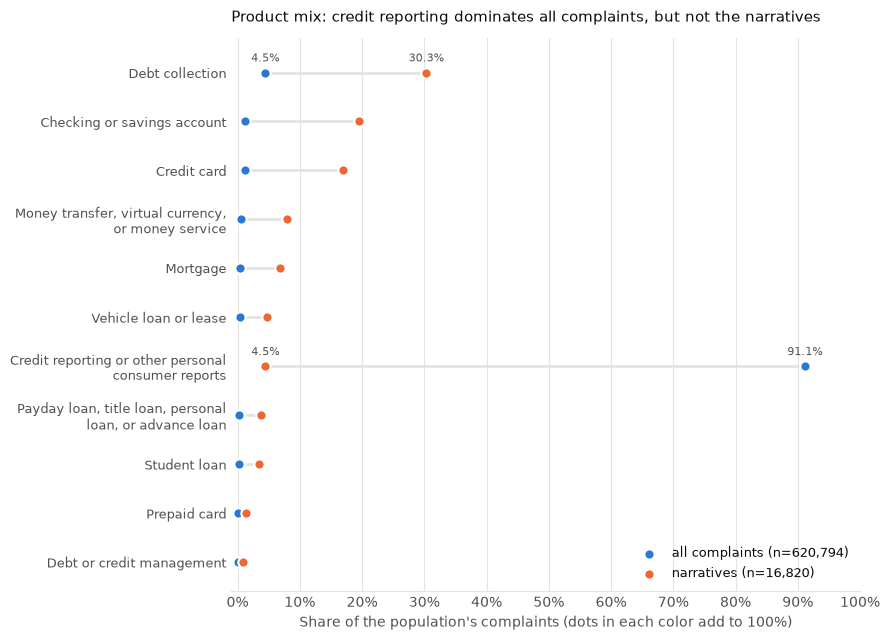

In [7]:
# --- Chart: product mix, all complaints vs. narratives ----------------------
# Chart colors for every chart in the notebook: blue = all complaints, orange = narratives
# (a colorblind-safe pair), plus grays for text and gridlines
POP_COLORS = {"all complaints": "#2a78d6", "narratives": "#eb6834"}
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

# Plot: products sorted by narrative share, highest at the top
mix = by_product.sort_values("narrative_%")
y = np.arange(len(mix))

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.hlines(y, mix["all_%"], mix["narrative_%"], color=GRID, lw=2, zorder=1)
for col, name in [("all_%", "all complaints"), ("narrative_%", "narratives")]:
    total = mix[col.replace("%", "n")].sum()
    ax.scatter(mix[col], y, s=55, color=POP_COLORS[name], edgecolor="white", linewidth=1.5, zorder=3,
               label=f"{name} (n={total:,})")

# Direct labels on the two products that move the most
for product in ["Credit reporting or other personal consumer reports", "Debt collection"]:
    row = y[mix.index.get_loc(product)]
    for col in ["all_%", "narrative_%"]:
        ax.annotate(f"{mix.loc[product, col]:.1f}%", (mix.loc[product, col], row), xytext=(0, 8),
                    textcoords="offset points", ha="center", fontsize=8, color=INK_MUTED)

ax.set_yticks(y, [textwrap.fill(p, 34) for p in mix.index], fontsize=9, color=INK)
ax.set_ylim(-0.6, len(mix) - 0.3)
ax.set_xlim(-1, 100)
ax.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(10))
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals=0))
ax.set_xlabel("Share of the population's complaints (dots in each color add to 100%)", color=INK_MUTED)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=INK_MUTED, length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=INK)
ax.set_title("Product mix: credit reporting dominates all complaints, but not the narratives",
             loc="left", fontsize=11, color=INK, pad=12)
fig.tight_layout()
plt.show()

**How to read the chart**

Think of it as two pie charts drawn as dots, with one row per product:
- **Blue dot:** the product's share of all 620,794 complaints (the product mix of the full export).
- **Orange dot:** the product's share of the 16,820 narratives (the product mix of the narrative subset).
- **Each color adds to 100%** across the 11 products, so when one product's share shrinks, the others must grow.
- **Gray line:** the gap between the two shares. The longer the line, the more the narratives over- or under-represent that product.

*Example:* credit card has fewer narratives than complaints (2,840 vs. 7,453), as a subset must. But it is a bigger slice of a much smaller pie: 16.9% of narratives vs. 1.2% of all complaints.

**What it shows**

1. **Credit reporting nearly disappears:** 91.1% of all complaints, but 4.5% of narratives.
2. **Debt collection becomes the largest product:** 4.5% of all complaints, but 30.3% of narratives.
3. **Every other product gains share,** e.g. checking/savings 1.2% → 19.4% and credit card 1.2% → 16.9%.

**Why:** only 0.13% of credit-reporting complaints include a narrative (751 of 565,831), against 18.5% for debt collection, 33-44% for every other product, and 2.7% overall (`has_narrative_%` in the table above). The data does not say why.

**Implication:** the narratives are not a representative sample of the export. Anything learned from them, including the model, describes complaints led by debt collection, checking/savings and credit card, with very few about credit reporting. The same product mix explains why the overall relief rates of the two groups differ (Relief Patterns).

*Note:* shares here include complaints still 'In progress', so credit reporting reads 91.1% here vs. 91.2% of *closed* complaints in the relief charts.

### Target Candidates

Four columns could be the model's target, compared here within the narratives (the only complaints an LLM can read):
- **Company response to consumer** (relief): *how the complaint ended*, reported by the company. Evaluated first, in Candidate 1, and set aside.
- **Product, Sub-product, Issue:** *what the complaint is about*, picked by the consumer when filing. Evaluated in Candidates 2-4; **Issue is chosen**.

What the table measures:
- `classes_>=30` / `classes_>=100`: classes with enough narratives to score on their own.
- `classes_per_product`: how many options one product offers (Sub-product and Issue options depend on the product).
- `largest_%` / `top5_%`: how much the biggest classes dominate; a dominant class makes accuracy look high without meaning much.

In [8]:
# --- Explore: target candidates (narrative subset) --------------------------
TARGET_CANDIDATES = ["Company response to consumer", "Product", "Sub-product", "Issue"]  # in the order evaluated
MIN_CLASS_SMALL, MIN_CLASS_LARGE = 30, 100


def describe_target(col):
    """Class structure of one candidate target within the narrative subset."""
    vc = df_narrative[col].value_counts()
    per_product = df_narrative.groupby("Product")[col].nunique()
    return {
        "classes": len(vc),
        f"classes_>={MIN_CLASS_SMALL}": int((vc >= MIN_CLASS_SMALL).sum()),
        f"classes_>={MIN_CLASS_LARGE}": int((vc >= MIN_CLASS_LARGE).sum()),
        "classes_per_product": f"{per_product.min()}-{per_product.max()}",
        "largest_class": str(vc.index[0])[:45],
        "largest_%": round(100 * vc.iloc[0] / vc.sum(), 1),
        "top5_%": round(100 * vc.head(5).sum() / vc.sum(), 1),
    }


n_missing = int(df_narrative[TARGET_CANDIDATES].isna().sum().sum())
assert check("no missing labels in any candidate", n_missing == 0, f"(missing: {n_missing})")

targets = pd.DataFrame({col: describe_target(col) for col in TARGET_CANDIDATES}).T
display(targets)

PASS  no missing labels in any candidate  (missing: 0)


,classes,classes_>=30,classes_>=100,classes_per_product,largest_class,largest_%,top5_%
Company response to consumer,4,4,4,3-4,Closed with explanation,76.5,100.0
Product,11,11,11,1-1,Debt collection,30.3,81.4
Sub-product,52,37,26,2-11,Checking account,16.0,54.1
Issue,83,53,38,5-28,Attempts to collect debt not owed,13.7,40.8


#### Candidate 1: Relief Patterns

Could a model read a narrative and predict how the complaint ends (`Company response to consumer`)? This part describes which complaints end in relief, for all complaints and for the narratives; it fits no model. **Relief is set aside**; the four reasons are at the end of this part (*Why Relief Was Not Chosen as the Target*).

**What the response categories mean.** Companies "select the closure category that is supported by their actions and written response", one per complaint (CFPB, *2025 Consumer Response Annual Report*, published March 2026, section "Complaint response categories", pp. 12-13; https://files.consumerfinance.gov/f/documents/cfpb_2025-cr-annual-report_2026-03.pdf):
- *Closed with monetary relief*: "company reported providing objective, measurable, and verifiable monetary relief to the consumer as a direct result of the steps that have or will be taken in response to the complaint."
- *Closed with non-monetary relief*: "company reported providing other objective and verifiable relief to the consumer [...] (e.g., stopping unwanted calls from debt collectors; correcting account information; correcting inaccurate data provided or reported in a credit report; issuing corrected documents; restoring account access; and, addressing formerly unmet customer service issues)."
- *Closed with explanation*: "company reported that the complaint did not result in relief but provided a written explanation tailored to the issues raised by the consumer."

Two consequences for reading the rates: every category is *company-reported*, not verified by us, and the export has no dollar amounts. The quoted section does not define `Untimely response` or `In progress`; how we treat them below is our choice.

**How the rates are computed**
- **Monetary**, **non-monetary** and **any relief** (either of the two). Each complaint has one closure category, so monetary + non-monetary = any relief. The tables report monetary and any relief; the charts show monetary and non-monetary.
- `In progress` complaints have no final outcome and are excluded; `Untimely response` counts as closed without relief.
- Each rate has a 95% Wilson confidence interval (suited to small proportions).
- The company table ranks only companies with at least `MIN_GROUP_N` (100) complaints, so small ones can't top the list by chance.
- All rates are associations, not causes: a high rate says which complaints *tend* to end in relief, not why.

In [9]:
# --- Explore: relief patterns ----------------------------------------------
OUTCOME_COL = "Company response to consumer"
MONETARY = "Closed with monetary relief"
NON_MONETARY = "Closed with non-monetary relief"
MIN_GROUP_N = 100  # groups smaller than this are not ranked
TOP_N = 10
Z95 = 1.96


def wilson_ci(k, n, z=Z95):
    """95% Wilson score interval for the proportion k/n (works on arrays); returns (low, high)."""
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return center - half, center + half


def relief_table(df, by):
    """Monetary and any-relief rates per group with 95% CIs; 'In progress' complaints excluded."""
    closed = df[df[OUTCOME_COL] != "In progress"]
    grouped = closed.assign(
        monetary=closed[OUTCOME_COL].eq(MONETARY),
        any_relief=closed[OUTCOME_COL].isin([MONETARY, NON_MONETARY]),
    ).groupby(by)[["monetary", "any_relief"]]
    n = grouped.size()
    counts = grouped.sum()

    out = pd.DataFrame({"n": n})
    for name in ["monetary", "any_relief"]:
        low, high = wilson_ci(counts[name], n)
        out[f"{name}_%"] = (100 * counts[name] / n).round(1)
        out[f"{name}_95CI"] = [f"{100 * a:.1f}-{100 * b:.1f}" for a, b in zip(low, high)]
    return out


populations = {"all complaints": df_raw, "narratives": df_narrative}

# Overall baseline for each population
for name, df in populations.items():
    overall = relief_table(df.assign(_all="all"), "_all").iloc[0]
    print(f"{name:15} n={overall['n']:>8,}  monetary {overall['monetary_%']:4.1f}% ({overall['monetary_95CI']})  "
          f"any relief {overall['any_relief_%']:4.1f}% ({overall['any_relief_95CI']})")

# 1. Product: both populations side by side
by_product_relief = pd.concat({name: relief_table(df, "Product") for name, df in populations.items()}, axis=1)
display(by_product_relief.sort_values(("all complaints", "monetary_%"), ascending=False))

# 2. Company (narratives): top groups by monetary rate among companies with n >= MIN_GROUP_N
company = relief_table(df_narrative, "Company")
eligible = company[company["n"] >= MIN_GROUP_N]
print(f"\nCompany | narratives: top {TOP_N} by monetary relief "
      f"({len(eligible)} of {len(company)} companies have n >= {MIN_GROUP_N})")
display(eligible.sort_values("monetary_%", ascending=False).head(TOP_N))

all complaints  n= 620,346  monetary  0.5% (0.4-0.5)  any relief 35.2% (35.1-35.3)
narratives      n=  16,820  monetary  7.1% (6.7-7.5)  any relief 20.6% (20.0-21.2)


all complaints  \
                                                                     n   
Product                                                                  
Credit card                                                       7380   
Checking or savings account                                       7637   
Prepaid card                                                       521   
Money transfer, virtual currency, or money service                3025   
Payday loan, title loan, personal loan, or advance loan           1550   
Debt or credit management                                          362   
Vehicle loan or lease                                             1992   
Mortgage                                                          2940   
Student loan                                                      1712   
Debt collection                                                  27502   
Credit reporting or other personal consumer reports             565725   

                                                                    \
                                                        monetary_%   
Product                                                              
Credit card                                                   16.5   
Checking or savings account                                   13.4   
Prepaid card                                                  12.9   
Money transfer, virtual currency, or money service             9.2   
Payday loan, title loan, personal loan, or advance loan        3.3   
Debt or credit management                                      3.3   
Vehicle loan or lease                                          2.2   
Mortgage                                                       1.8   
Student loan                                                   0.4   
Debt collection                                                0.2   
Credit reporting or other personal consumer reports            0.0   

                                                                       \
                                                        monetary_95CI   
Product                                                                 
Credit card                                                 15.6-17.3   
Checking or savings account                                 12.7-14.2   
Prepaid card                                                10.3-16.0   
Money transfer, virtual currency, or money service           8.2-10.3   
Payday loan, title loan, personal loan, or advance loan       2.5-4.3   
Debt or credit management                                     1.9-5.7   
Vehicle loan or lease                                         1.6-3.0   
Mortgage                                                      1.4-2.3   
Student loan                                                  0.2-0.8   
Debt collection                                               0.1-0.2   
Credit reporting or other personal consumer reports           0.0-0.0   

                                                                      \
                                                        any_relief_%   
Product                                                                
Credit card                                                     26.0   
Checking or savings account                                     19.1   
Prepaid card                                                    18.2   
Money transfer, virtual currency, or money service              16.8   
Payday loan, title loan, personal loan, or advance loan          5.7   
Debt or credit management                                       18.8   
Vehicle loan or lease                                            9.1   
Mortgage                                                         5.4   
Student loan                                                     2.4   
Debt collection                                                 26.5   
Credit reporting or other personal consumer reports             36.5   

      


Company | narratives: top 10 by monetary relief (35 of 1024 companies have n >= 100)


,n,monetary_%,monetary_95CI,any_relief_%,any_relief_95CI
Company,,,,,
"BANK OF AMERICA, NATIONAL ASSOCIATION",599,35.9,32.2-39.8,40.4,36.5-44.4
"CITIBANK, N.A.",583,26.2,22.8-30.0,42.4,38.4-46.4
"Bread Financial Holdings, Inc.",134,25.4,18.8-33.4,51.5,43.1-59.8
"Paypal Holdings, Inc",496,24.4,20.8-28.4,46.6,42.2-51.0
TD BANK US HOLDING COMPANY,137,19.0,13.3-26.4,40.1,32.3-48.5
AMERICAN EXPRESS COMPANY,256,17.6,13.4-22.7,23.0,18.3-28.6
UNITED SERVICES AUTOMOBILE ASSOCIATION,116,16.4,10.7-24.2,22.4,15.8-30.8
SYNCHRONY FINANCIAL,380,15.3,12.0-19.2,17.9,14.4-22.1
WELLS FARGO & COMPANY,562,13.0,10.5-16.0,23.5,20.2-27.2


##### Chart: Monetary Relief by Product

The product table above as a picture: one row per product, one dot per population (all complaints vs. narratives) with its 95% Wilson CI. Dashed lines mark each population's overall rate. Same rules as `relief_table()` ('In progress' excluded), and the cell checks that its numbers match that table before plotting.

PASS  all complaints: n per product matches relief_table  (expected total 620,346, actual 620,346)
PASS  all complaints: rate per product matches relief_table  (max abs difference 0.0 points)
PASS  all complaints: every rate inside its CI  
PASS  narratives: n per product matches relief_table  (expected total 16,820, actual 16,820)
PASS  narratives: rate per product matches relief_table  (max abs difference 0.0 points)
PASS  narratives: every rate inside its CI  


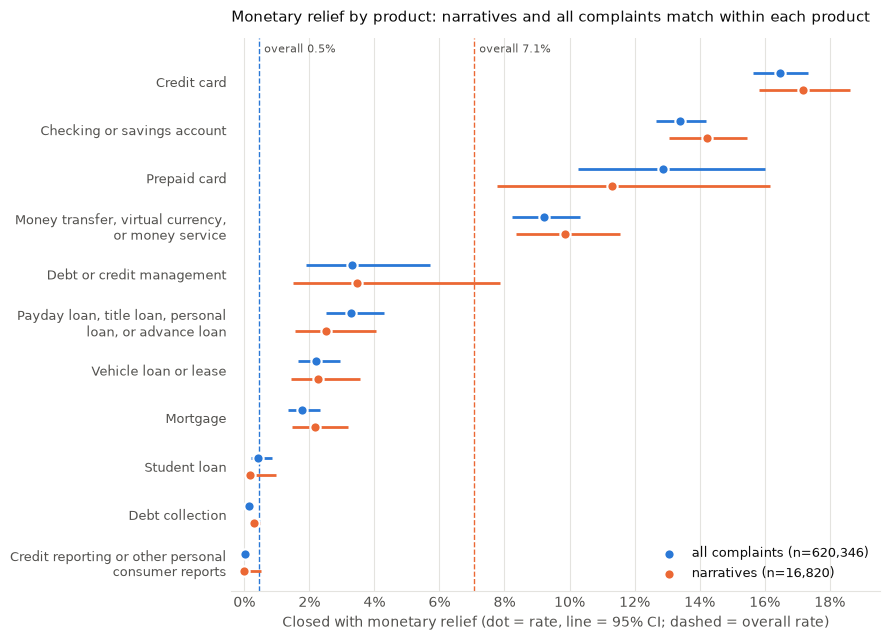

In [10]:
# --- Chart: monetary relief by product -------------------------------------
DODGE = 0.18  # vertical offset within a row so the two CIs don't overlap


def relief_points(df, outcome):
    """Rate of one outcome and its 95% Wilson CI (in %) per product; 'In progress' excluded."""
    closed = df[df[OUTCOME_COL] != "In progress"]
    is_outcome = closed[OUTCOME_COL].eq(outcome).groupby(closed["Product"])
    k, n = is_outcome.sum(), is_outcome.size()
    low, high = wilson_ci(k, n)
    return pd.DataFrame({"n": n, "k": k, "rate": 100 * k / n, "low": 100 * low, "high": 100 * high})


def plot_relief_dots(points, xlabel, title, tick_step):
    """Dot plot per product, one dot + CI per population, sorted by the all-complaints rate (highest on top)."""
    order = points["all complaints"].sort_values("rate").index
    y = np.arange(len(order))

    fig, ax = plt.subplots(figsize=(9, 6.5))
    for offset, (name, pts) in zip([DODGE, -DODGE], points.items()):
        pts = pts.reindex(order)
        color = POP_COLORS[name]
        overall = 100 * pts["k"].sum() / pts["n"].sum()
        ax.axvline(overall, color=color, lw=1, ls="--", zorder=1)
        ax.text(overall + 0.15, len(order) - 0.45, f"overall {overall:.1f}%", color=INK_MUTED, fontsize=8, va="bottom")
        ax.hlines(y + offset, pts["low"], pts["high"], color=color, lw=2, zorder=2)
        ax.scatter(pts["rate"], y + offset, s=55, color=color, edgecolor="white", linewidth=1.5, zorder=3,
                   label=f"{name} (n={pts['n'].sum():,})")

    ax.set_yticks(y, [textwrap.fill(p, 34) for p in order], fontsize=9, color=INK)
    ax.set_ylim(-0.6, len(order) - 0.1)
    ax.set_xlim(-0.4, None)  # just below 0 so dots at 0% aren't clipped
    ax.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(tick_step))
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals=0))
    ax.set_xlabel(f"{xlabel} (dot = rate, line = 95% CI; dashed = overall rate)", color=INK_MUTED)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=INK)
    ax.set_title(title, loc="left", fontsize=11, color=INK, pad=12)
    fig.tight_layout()
    plt.show()


monetary_points = {name: relief_points(df_pop, MONETARY) for name, df_pop in populations.items()}

# Checks: the plotted numbers must match relief_table(), and each dot must sit inside its CI
results = []
for name, df_pop in populations.items():
    expected = relief_table(df_pop, "Product")
    pts = monetary_points[name].reindex(expected.index)
    rate_diff = (pts["rate"].round(1) - expected["monetary_%"]).abs().max()
    results += [
        check(f"{name}: n per product matches relief_table", (pts["n"] == expected["n"]).all(),
              f"(expected total {expected['n'].sum():,}, actual {pts['n'].sum():,})"),
        check(f"{name}: rate per product matches relief_table", rate_diff == 0,
              f"(max abs difference {rate_diff:.1f} points)"),
        check(f"{name}: every rate inside its CI", pts["rate"].between(pts["low"], pts["high"]).all()),
    ]
assert all(results), "A chart check failed; see the FAIL lines above"

plot_relief_dots(monetary_points, xlabel="Closed with monetary relief", tick_step=2,
                 title="Monetary relief by product: narratives and all complaints match within each product")

**How to read the chart**

- **Dot:** the share of a product's closed complaints that ended in monetary relief (it counts complaints, not dollars). Blue = all complaints, orange = narratives. *Example:* 488 of 2,840 credit-card narratives (17.2%) got monetary relief, vs. 16.5% of all 7,380 closed credit-card complaints.
- **Line through the dot:** the 95% confidence interval, the plausible range given how many complaints the group has. Big groups get short lines, small groups long ones. **If a row's two lines overlap, the data can't tell the two groups apart.**
- **Dashed lines:** each group's overall rate across all products, 0.5% for all complaints (2,855 of 620,346) and 7.1% for narratives (1,190 of 16,820). They are weighted by how many complaints each product has, so they mostly reflect the product mix.
- Gaps are in percentage points: credit card 16.5% vs. mortgage 1.8% is a 14.7-point gap.

**What it shows**

1. **Product drives the rate.** Credit card, checking/savings, prepaid card and money transfer sit at about 9-17%; every other product is under 4%, and credit reporting is about 0%.
2. **Within each product, narratives match all complaints.** In every row the blue and orange CIs overlap. Debt collection overlaps only narrowly (0.15% vs. 0.29%), a gap of about 0.1 points at a very low rate.
3. **The overall gap (0.5% vs. 7.1%) comes from product mix, not from the narrative.** Credit reporting (about 0%) is 91.2% of all closed complaints but only 4.5% of narratives. The four high-relief products are 3.0% of all complaints but 45.6% of narratives. Comparing the dashed lines alone would wrongly suggest narratives are about 14 times more likely to get monetary relief.

**Limits.** The categories are company-reported, and the export has no dollar amounts. For the report, quote narrative relief rates per product, or state that the overall 7.1% reflects the product mix.

##### Chart: Non-Monetary Relief by Product

Same layout as the monetary chart, for `Closed with non-monetary relief`. Each complaint has one closure category, so for every product monetary + non-monetary = any relief; the cell checks that against `relief_table()` before plotting, and lists the products where the two populations' CIs do not overlap.

PASS  all complaints: n per product matches relief_table  (expected total 620,346, actual 620,346)
PASS  all complaints: monetary + non-monetary = any relief  (max abs difference 0.0 points)
PASS  all complaints: every rate inside its CI  
PASS  narratives: n per product matches relief_table  (expected total 16,820, actual 16,820)
PASS  narratives: monetary + non-monetary = any relief  (max abs difference 0.0 points)
PASS  narratives: every rate inside its CI  

CIs that don't overlap (2 of 11 products):
  Credit reporting or other personal consumer reports: all 36.5% (36.4-36.6) vs. narratives 40.9% (37.4-44.4)
  Debt collection: all 26.3% (25.8-26.9) vs. narratives 24.3% (23.2-25.5)


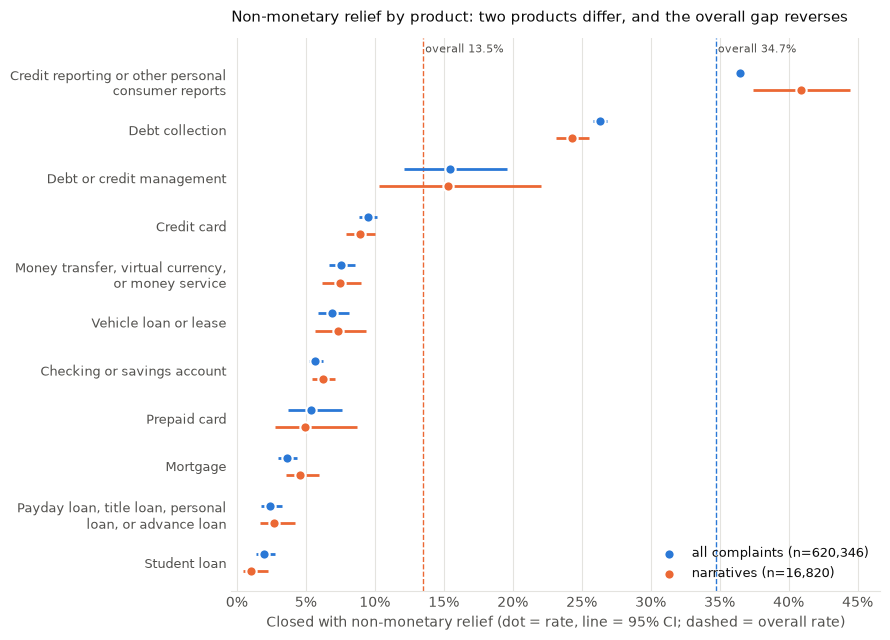

In [11]:
# --- Chart: non-monetary relief by product ---------------------------------
non_monetary_points = {name: relief_points(df_pop, NON_MONETARY) for name, df_pop in populations.items()}

# Checks: n matches relief_table(); monetary + non-monetary counts reproduce its any-relief rate
results = []
for name, df_pop in populations.items():
    expected = relief_table(df_pop, "Product")
    pts = non_monetary_points[name].reindex(expected.index)
    any_k = pts["k"] + monetary_points[name].reindex(expected.index)["k"]
    any_diff = ((100 * any_k / pts["n"]).round(1) - expected["any_relief_%"]).abs().max()
    results += [
        check(f"{name}: n per product matches relief_table", (pts["n"] == expected["n"]).all(),
              f"(expected total {expected['n'].sum():,}, actual {pts['n'].sum():,})"),
        check(f"{name}: monetary + non-monetary = any relief", any_diff == 0,
              f"(max abs difference {any_diff:.1f} points)"),
        check(f"{name}: every rate inside its CI", pts["rate"].between(pts["low"], pts["high"]).all()),
    ]
assert all(results), "A chart check failed; see the FAIL lines above"

# Products where the two populations' CIs don't overlap
all_pts = non_monetary_points["all complaints"]
nar_pts = non_monetary_points["narratives"].reindex(all_pts.index)
no_overlap = (nar_pts["low"] > all_pts["high"]) | (nar_pts["high"] < all_pts["low"])
print(f"\nCIs that don't overlap ({no_overlap.sum()} of {len(no_overlap)} products):")
for product in all_pts.index[no_overlap]:
    a, b = all_pts.loc[product], nar_pts.loc[product]
    print(f"  {product}: all {a['rate']:.1f}% ({a['low']:.1f}-{a['high']:.1f}) "
          f"vs. narratives {b['rate']:.1f}% ({b['low']:.1f}-{b['high']:.1f})")

plot_relief_dots(non_monetary_points, xlabel="Closed with non-monetary relief", tick_step=5,
                 title="Non-monetary relief by product: two products differ, and the overall gap reverses")

**Reading the chart**

Read it like the monetary chart above (same unit, CIs and percentage points). Non-monetary relief means the company reported a concrete, non-cash fix, such as correcting a credit report or stopping collection calls (CFPB definition quoted under Relief Patterns). Because each complaint has one closure category, a product's monetary rate (chart above) plus its non-monetary rate (this chart) is its any-relief rate.

**What it shows**

1. **The overall gap reverses.** Narratives have the *lower* overall rate here: 13.5% (2,272 of 16,820) vs. 34.7% (215,435 of 620,346) for all complaints, the opposite of the monetary chart (7.1% vs. 0.5%). The cause is the same product mix: credit reporting has the highest non-monetary rate and is 91.2% of all closed complaints but only 4.5% of narratives.
2. **Two products differ within the product** (their CIs don't overlap):
   - *Credit reporting*: narratives higher, 40.9% (37.4-44.4) vs. 36.5% (36.4-36.6), a 4.4-point gap.
   - *Debt collection*: narratives lower, 24.3% (23.2-25.5) vs. 26.3% (25.8-26.9), a 2.0-point gap.
3. **The other nine products match**, as in the monetary chart.

**Limits.** The data shows that these two gaps exist, not why. The narrative itself, the kind of issue people write about, or how companies respond to written complaints could each play a part; nothing here separates them.

**Implication.** For both relief types, most of the difference between narratives and all complaints comes from product mix; within products, narratives mostly look like all complaints, except credit reporting and debt collection here. What this means for relief as a target is in the next cell.

##### Why Relief Was Not Chosen as the Target

Four reasons, from the tables and charts above:

1. **The classes do not separate cleanly.** If monetary relief is the thing to predict, every other outcome falls into one "not monetary" class. That class would mix *Closed with non-monetary relief* (the company made a concrete fix) with *Closed with explanation*, which CFPB defines as no relief at all. Two very different outcomes would share one label, and which of the two a complaint gets depends on how the company reports its own response.
2. **One class dominates.** *Closed with explanation* is 76.5% of narratives (Target Candidates table above), and monetary relief is 7.1% (1,190 of 16,820). A model that always predicts "no relief" would look accurate without reading anything.
3. **The structured fields already explain most of it.** Product drives the relief rate: monetary relief is about 9-17% for credit card, checking/savings, prepaid card and money transfer, under 4% for the other products, and about 0% for credit reporting. The company matters too: among narratives, Bank of America gave monetary relief in 35.9% of complaints and Wells Fargo in 13.0%. Most of the answer is known before anyone reads the narrative.
4. **Having a narrative makes little difference.** Within a product, complaints with a narrative get relief at about the same rate as all complaints. For monetary relief, every product's confidence intervals overlap; for non-monetary relief, only credit reporting (+4.4 points) and debt collection (-2.0 points) differ. The overall gaps come from product mix.

**Next:** the three remaining candidates, labels the consumer picks to describe their own complaint, so the narrative itself should carry the signal.

#### Candidates 2-4: Product, Sub-product and Issue

With relief set aside, the search moves to the three labels the consumer picks when filing: Product first, then a Sub-product and an Issue from the options that Product offers. Each describes *what the complaint is about*, which is what the narrative is written to explain. The practical question: does each class have enough narratives to train and score a model?

##### Chart: Class Sizes per Target Candidate

One panel per candidate, one dot per class, on a log scale; dashed lines mark `MIN_CLASS_SMALL` (30) and `MIN_CLASS_LARGE` (100) narratives. Counts include duplicate narratives; the deduplicated Issue counts are in Clean > Modeling Set: Issue Class Sizes.

PASS  Product: classes / >=30 / >=100 match the table  (expected (11, 11, 11), actual (11, 11, 11))
PASS  Product: classes add up to all narratives  (16,820 of 16,820)
PASS  Sub-product: classes / >=30 / >=100 match the table  (expected (52, 37, 26), actual (52, 37, 26))
PASS  Sub-product: classes add up to all narratives  (16,820 of 16,820)
PASS  Issue: classes / >=30 / >=100 match the table  (expected (83, 53, 38), actual (83, 53, 38))
PASS  Issue: classes add up to all narratives  (16,820 of 16,820)


,classes >=100,narratives >=100,% >=100,classes 30-99,narratives 30-99,% 30-99,classes <30,narratives <30,% <30
Product,11.0,16820.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0
Sub-product,26.0,15927.0,94.7,11.0,673.0,4.0,15.0,220.0,1.3
Issue,38.0,15683.0,93.2,15.0,886.0,5.3,30.0,251.0,1.5


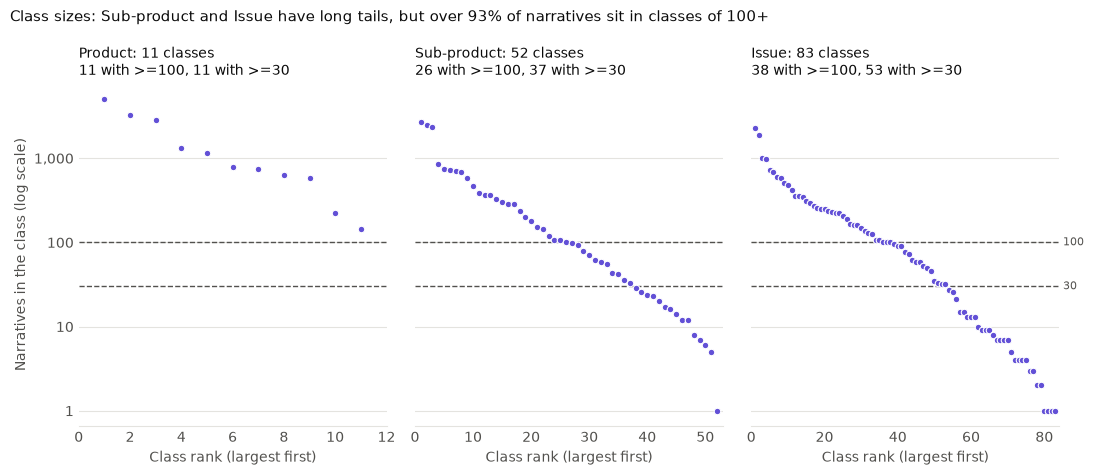

In [12]:
# --- Chart: class sizes per target candidate --------------------------------
CLASS_TARGETS = ["Product", "Sub-product", "Issue"]  # Company response is an outcome, not a "what is it about" label
CLASS_COLOR = "#6250d6"  # palette slot 7; blue/orange stay reserved for all complaints vs. narratives

class_sizes = {col: df_narrative[col].value_counts() for col in CLASS_TARGETS}

# Checks: class counts match the Target Candidates table, and each target's classes cover every narrative
results = []
for col, vc in class_sizes.items():
    row = targets.loc[col]
    expected = (int(row["classes"]), int(row[f"classes_>={MIN_CLASS_SMALL}"]), int(row[f"classes_>={MIN_CLASS_LARGE}"]))
    actual = (len(vc), int((vc >= MIN_CLASS_SMALL).sum()), int((vc >= MIN_CLASS_LARGE).sum()))
    results += [
        check(f"{col}: classes / >=30 / >=100 match the table", actual == expected, f"(expected {expected}, actual {actual})"),
        check(f"{col}: classes add up to all narratives", vc.sum() == len(df_narrative), f"({vc.sum():,} of {len(df_narrative):,})"),
    ]
assert all(results), "A chart check failed; see the FAIL lines above"

# How many classes, and narratives, sit in each class-size band (band_summary is reused in Clean)
def band_summary(vc: pd.Series) -> dict:
    """Classes and narratives in each class-size band."""
    bands_ = {">=100": vc >= MIN_CLASS_LARGE, "30-99": vc.between(MIN_CLASS_SMALL, MIN_CLASS_LARGE - 1), "<30": vc < MIN_CLASS_SMALL}
    out = {}
    for name, mask in bands_.items():
        out[f"classes {name}"] = int(mask.sum())
        out[f"narratives {name}"] = int(vc[mask].sum())
        out[f"% {name}"] = round(100 * vc[mask].sum() / vc.sum(), 1)
    return out


bands = pd.DataFrame({col: band_summary(vc) for col, vc in class_sizes.items()}).T
display(bands)

# Plot: one panel per target, shared log y-axis
fig, axes = plt.subplots(1, 3, figsize=(11, 4.8), sharey=True)
for ax, (col, vc) in zip(axes, class_sizes.items()):
    rank = np.arange(1, len(vc) + 1)
    ax.scatter(rank, vc.values, s=22, color=CLASS_COLOR, edgecolor="white", linewidth=0.8, zorder=3)
    for threshold in [MIN_CLASS_SMALL, MIN_CLASS_LARGE]:
        ax.axhline(threshold, color=INK_MUTED, lw=1, ls="--", zorder=1)
    n30, n100 = int((vc >= MIN_CLASS_SMALL).sum()), int((vc >= MIN_CLASS_LARGE).sum())
    ax.set_title(f"{col}: {len(vc)} classes\n{n100} with >=100, {n30} with >=30", loc="left", fontsize=10, color=INK)
    ax.set_yscale("log")
    ax.set_xlim(0, len(vc) + 1)
    ax.set_xlabel("Class rank (largest first)", color=INK_MUTED)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(which="both", colors=INK_MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

axes[0].yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].set_ylabel("Narratives in the class (log scale)", color=INK_MUTED)
for threshold in [MIN_CLASS_SMALL, MIN_CLASS_LARGE]:
    axes[-1].text(axes[-1].get_xlim()[1], threshold, f" {threshold}", va="center", ha="left", fontsize=8, color=INK_MUTED)
fig.suptitle("Class sizes: Sub-product and Issue have long tails, but over 93% of narratives sit in classes of 100+", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
plt.show()

**How to read the chart**

- **Each dot is one class** (e.g. one Issue), ranked from largest (left) to smallest (right). Its height is how many narratives carry that label.
- **Log scale:** each gridline is 10 times the one below (1, 10, 100, 1,000), so classes of 5 narratives stay visible next to classes of thousands.
- **Dashed lines at 30 and 100** mark how much data a class needs to be scored on its own. A test set gets only part of each class, and small samples give wide confidence intervals: 80% recall measured on 6 test examples has a 95% CI of about 44-97%, on 30 examples about 63-90%. So under 30 a class can't be scored reliably, 30-99 can be scored with wide CIs, and 100+ can be scored on its own. These are rules of thumb, not fixed standards.

**What it shows** (from the table above the chart)

1. **Product:** all 11 classes have at least 100 narratives (smallest: 144), so every class can be scored.
2. **Sub-product:** 26 of 52 classes have 100+, holding 15,927 narratives (94.7%). The 15 classes under 30 hold only 220 narratives (1.3%).
3. **Issue:** 38 of 83 classes have 100+, holding 15,683 narratives (93.2%). The 30 classes under 30 hold only 251 narratives (1.5%).
4. **The long tails are thin.** Sub-product and Issue have many small classes, but those classes hold few narratives.

**Decision: Issue is the target.** It is the label that best fits a model reading the narrative:
- **Most specific.** Product names the kind of account ("Debt collection"); Issue names what went wrong ("Attempts to collect debt not owed"), which is what a narrative is written to explain.
- **Enough data to score.** Its 38 classes of 100+ hold 93.2% of narratives; the 30 classes under 30 hold only 1.5%.

All 83 Issues stay as classes, with no merging into "Other": Issue options depend on Product and Sub-product, so merging or dropping rare classes would remove options consumers actually see (for Payday loans, 18 of the 28 Issues used have under 30 narratives).

### Duplicate Narratives

Some narratives appear more than once. Copies that land in both the training and the test set let the baseline score on text it has already seen, so its results would look better than they are. Two types turn up in the 16,820 narratives:
- **Type 1: the same text filed more than once.** Copies count as the same text after ignoring punctuation and capitals.
- **Type 2: a template.** One script copied over and over with only the collector's name and the account number changed, so the copies are not identical text.

**Result:** both types are removed in Clean. Together with the form check in the next section, 14,755 narratives remain for modeling, still covering all 83 Issues.

#### Type 1: The Same Text Filed More Than Once

Two narratives are copies when their whole text matches after normalizing: lowercase, punctuation turned into spaces, whitespace collapsed. Redaction marks (XXXX) stay, because CFPB applies them to every narrative. The normalized form is used only for matching; the models read the original text.

In [13]:
# --- Duplicates, Type 1: the same text filed more than once -----------------
# Clean reuses comparison_key().
def comparison_key(text: pd.Series) -> pd.Series:
    """Lowercase, punctuation to spaces, collapse whitespace, trim. Redaction marks (XXXX) are kept."""
    return (text.str.lower()
                .str.replace(r"[^\w\s]", " ", regex=True)
                .str.replace(r"\s+", " ", regex=True)
                .str.strip())


texts = df_narrative[NARRATIVE_COL]
narr_key = comparison_key(texts)
exact_extra = int(texts.duplicated().sum())
key_extra = int(narr_key.duplicated().sum())
expected_exact = len(texts) - int(profile.loc[NARRATIVE_COL, "n_unique"])

results = [
    check("exact copies match the structure profile", exact_extra == expected_exact,
          f"(expected {expected_exact:,}, actual {exact_extra:,})"),
    check("normalizing never finds fewer copies", key_extra >= exact_extra, f"(exact {exact_extra:,}, normalized {key_extra:,})"),
    check("no empty keys", (narr_key != "").all(), f"(empty: {(narr_key == '').sum():,})"),
]
assert all(results), "A duplicate check failed; see the FAIL lines above"

print(f"\nExtra copies, exact text:        {exact_extra:,}")
print(f"Extra copies, after normalizing: {key_extra:,} ({100 * key_extra / len(texts):.1f}% of {len(texts):,} narratives)")


def first_difference(a: str, b: str, width: int = 25) -> str:
    """Both texts around the first character where they differ."""
    i = next((k for k, (x, y) in enumerate(zip(a, b)) if x != y), min(len(a), len(b)))
    lo = max(0, i - width)
    return f"{a[lo:i + width]!r}  vs.  {b[lo:i + width]!r}"


# What normalizing adds: texts that differ only in punctuation or capitals
variants = texts.groupby(narr_key).agg(copies="size", raw_texts="nunique")
merged = variants[variants["raw_texts"] > 1].sort_values("copies", ascending=False)
examples = []
for key in merged.index:   # three different kinds of difference, from the most-copied texts
    a, b = sorted(texts[narr_key == key].unique()[:2], key=len)
    diff = first_difference(a, b)
    if diff not in examples:
        examples.append(diff)
    if len(examples) == 3:
        break
print(f"\nNormalizing merges {len(merged):,} groups of slightly different texts, for example:")
for diff in examples:
    print("  ", diff)

# The largest groups: how many copies, and across how many companies
groups = df_narrative.groupby(narr_key).agg(copies=("Complaint ID", "size"), companies=("Company", "nunique"),
                                             issues=("Issue", "nunique"))
repeated = groups[groups["copies"] > 1]
print(f"\nTexts that repeat: {len(repeated):,}, covering {repeated['copies'].sum():,} narratives")
largest = repeated.sort_values("copies", ascending=False).head(5).reset_index(drop=True)
largest["starts_with"] = [texts[narr_key == k].iloc[0][:70] for k in
                          repeated.sort_values("copies", ascending=False).head(5).index]
display(largest)

# Do the copies of a text agree on Issue?
disagree = int((repeated["issues"] > 1).sum())
print(f"Repeated texts whose copies disagree on Issue: {disagree} of {len(repeated):,}")

PASS  exact copies match the structure profile  (expected 1,440, actual 1,440)
PASS  normalizing never finds fewer copies  (exact 1,440, normalized 1,488)
PASS  no empty keys  (empty: 0)

Extra copies, exact text:        1,440
Extra copies, after normalizing: 1,488 (8.8% of 16,820 narratives)

Normalizing merges 44 groups of slightly different texts, for example:
   'gnificant stress and XXXX affecting my mental heal'  vs.  'gnificant stress and XXXX, affecting my mental hea'
   'edit!! Account number is XXXX is falsely reporting'  vs.  'edit!! Account number is # XXXX is falsely reporti'
   'ile a complaint against JEFFERSON CAPITAL LLC for '  vs.  'ile a complaint against Jefferson Capital, LLC for'

Texts that repeat: 329, covering 1,817 narratives


,copies,companies,issues,starts_with
0,278,93,1,This debt collector has engaged in conduct that violates the Fair Debt
1,194,3,1,There are collection accounts on my report that I believe contain inac
2,96,47,1,I am writing to formally request debt validation for a collection acco
3,45,31,1,I am formally disputing the validity of the alleged collection and cha
4,31,18,1,Delete this account because you can not furnish any documentation that


Repeated texts whose copies disagree on Issue: 14 of 329


**Findings**
- **1,440 extra copies of exact text**; normalizing adds 48 more that differ only by a comma, a "#" before a redaction mark, or capitals: **1,488 in all (8.8% of narratives)**.
- The largest groups run to hundreds of copies across dozens of companies (the top text: 278 copies, 93 companies), so some texts look like shared scripts rather than one person's complaint.
- Copies almost always agree on Issue: 14 of 329 repeated texts disagree.

#### Type 2: The Template Family

One script recurs with only the collector's name and the redacted account number changed, so Type 1 cannot merge the copies:

> *"[collector] is falsely reporting on my credit. I have never had any accounts with them. Per my research [collector] is a debt collector..."*

A narrative belongs to the family when it contains at least 2 of the script's 4 fixed sentences (2, not 4, because some copies have typos or are cut off).

In [14]:
# --- Duplicates, Type 2: the template family -------------------------------
# Clean reuses these definitions.
# The script's four fixed sentences, in comparison-key form (lowercase, no punctuation)
TEMPLATE_SIGNATURES = [
    "is falsely reporting on my credit i have never had any accounts with them",
    "is a debt collector they are falsely reporting on my credit",
    "is falsely reporting to my credit file and is against my rights and fair credit act",
    "of investigation consumer report you are in violation",
]
TEMPLATE_MIN_HITS = 2  # 2 of 4 tolerates the typos and cut-off text seen in some copies


def template_signature_hits(key: pd.Series) -> pd.Series:
    """Number of template sentences each comparison key contains (0 to len(TEMPLATE_SIGNATURES))."""
    return sum(key.str.contains(sig, regex=False).astype(int) for sig in TEMPLATE_SIGNATURES)


template_hits = template_signature_hits(narr_key)
is_template = template_hits >= TEMPLATE_MIN_HITS
family_rows = df_narrative[is_template]
n_partial = int(template_hits.between(1, TEMPLATE_MIN_HITS - 1).sum())

results = [
    check("family found", is_template.any(),
          f"({len(family_rows):,} complaints, {narr_key[is_template].nunique():,} different texts after normalizing)"),
    check("no narrative sits just below the threshold", n_partial == 0, f"(expected 0, actual {n_partial:,})"),
]
assert all(results), "A template-family check failed; see the FAIL lines above"
print("Fixed sentences matched per complaint:", template_hits[is_template].value_counts().sort_index().to_dict())

# Two copies: the same script with a different collector's name
print()
for key in narr_key[is_template].value_counts().index[:2]:
    print(textwrap.fill(texts[narr_key == key].iloc[0], width=110), "\n")

# Same labels, different filers
cols = ["Product", "Sub-product", "Issue", "Sub-issue", "Submitted via", "Company", "State", "ZIP code", "Date received"]
family_profile = pd.DataFrame({
    "distinct values": family_rows[cols].nunique(),
    "most common": family_rows[cols].mode().iloc[0],
    "most common %": (100 * family_rows[cols].apply(lambda s: s.value_counts().iloc[0]) / len(family_rows)).round(1),
})
display(family_profile)

PASS  family found  (322 complaints, 149 different texts after normalizing)
PASS  no narrative sits just below the threshold  (expected 0, actual 0)
Fixed sentences matched per complaint: {2: 1, 3: 13, 4: 308}

CREDIT COLL is falsely reporting on my credit. I have never had any accounts with them. Per my research CREDIT
COLL is a debt collector. They are falsely reporting on my credit!! Account number is # XXXX is falsely
reporting to my credit file and is against my rights and fair credit act. Under U.S Code 1618d - Disclosure of
investigation consumer report ; you are in violation. 

JEFFCAPSYS is falsely reporting on my credit. I have never had any accounts with them. Per my research
JEFFCAPSYS is a debt collector. They are falsely reporting on my credit!! Account number is XXXX is falsely
reporting to my credit file and is against my rights and fair credit act. Under U.S Code 1618d - Disclosure of
investigation consumer report ; you are in violation. 



,distinct values,most common,most common %
Product,1,Debt collection,100.0
Sub-product,1,I do not know,100.0
Issue,1,Attempts to collect debt not owed,100.0
Sub-issue,2,Debt was result of identity theft,99.4
Submitted via,1,Web,100.0
Company,28,CL Holdings LLC,22.0
State,27,FL,21.4
ZIP code,186,61821,4.0
Date received,20,2026-06-09,14.6


**Findings**
- **322 complaints (149 different texts, 1.9% of narratives)** follow the script.
- **The labels are identical:** all are Debt collection / Sub-product "I do not know" / Issue "Attempts to collect debt not owed", and 99.4% have Sub-issue "Debt was result of identity theft". All came through the web form.
- **The filers are not:** 186 ZIP codes, 27 states, 28 companies and 20 filing dates. A single filer is unlikely; an advocacy group or credit-repair service handing out a script would fit, but the data cannot say who wrote it.

#### Decision

Clean applies these rules to the narratives and logs every drop:
1. **Template family: drop every copy.** Keeping one copy per variant would still leave many near-identical texts with one shared label, which would give the baseline easy answers if they split across train and test.
2. **Copies that disagree on Issue: keep the majority Issue**, and drop the text on a tie (7 texts). The same words carry different labels, so the label a model learns from them is uncertain.
3. **All other copies: keep one per normalized text**, the first in file order.

**Result:** with the form check in the next section, 14,755 narratives remain for modeling, still covering all 83 Issues. The Explore sections keep every row, since each complaint is a real filing.

**Limitations.** Only this one template was searched for by its wording. Other scripts that vary in more than formatting would survive as separate narratives; similarity matching (e.g. TF-IDF cosine) could look for them.

### Issues vs. the Complaint Form

A consumer picks a Product and Sub-product first; the form then offers a fixed menu of Issues for that pair. The CFPB publishes every menu in its complaint form options document (`reference/cfpb_consumer_complaint_form_product_issue_options_August_2023_FINAL.pdf`, August 2023, the latest major revision). If the data agree with the form, every narrative's Issue is on its menu.

Checking 16,820 narratives against a 40-page PDF by hand is not practical, so Claude Code ran the check in code: the first cell reads the form's tables into menus (the parser from Assignment 7), the second compares each narrative's Issue to its menu. Modeling reuses the same menus as the options in the LLM prompt.

In [15]:
# --- Explore: read the complaint form into Issue menus ------------------------
# Result: printed_menus, (Product, Sub-product) -> {Issue: the form's description}. Clean and Modeling reuse it.
# How it works: a PDF stores each piece of text with its position, font and size. The form's product pages are
# tables (sub-product | issue | sub-issue), so each piece is placed in a column by its x position, and the
# formatting tells what it is: bold 12pt = sub-product name, a Wingdings bullet = start of an Issue.

# Layout of the form's product pages (measured from the PDF; units are PDF points)
FORM_PAGES = range(6, 39)     # product tables; later pages are the change-log appendix
SUB_COL_MAX_X = 280           # sub-product column is left of this
ISSUE_COL_MAX_X = 600         # issue column sits between the two; sub-issues start at x=613 or later
TABLE_TOP_Y = 500             # text above this is the page title
WRAP_GAP = 16                 # a label line this close below another label is the same name, wrapped
GROUP_GAP = 35                # sub-products this close share one issue list; a wider gap starts a new row

# Form spelling -> data spelling
SUBPRODUCT_RENAMES = {
    "CD": "CD (Certificate of Deposit)",
    "International money transfer (remittance)": "International money transfer",
    "Federal student loan": "Federal student loan servicing",
}
ISSUE_RENAMES = {"Charged up-front or unexpected fees": "Charged upfront or unexpected fees"}
# A starred option is not a real Issue: this one sends the consumer to the credit reporting product
CREDIT_REPORT_REDIRECT = "Problem with credit report or credit score"

CHANGE_NOTE = re.compile(r"\(\s*(added|revised|moved|split|removed)\s*\)", re.IGNORECASE)


def clean_form_text(text):
    """Join line breaks, straighten curly quotes, drop change notes like '(added)'."""
    text = text.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    return re.sub(r"\s+", " ", CHANGE_NOTE.sub("", text)).strip()


def split_description(text):
    """'Managing an account (deposits, ...)' -> ('Managing an account', 'deposits, ...')."""
    match = re.match(r"^(.*?)\s*\((.*)\)$", text)
    return (match.group(1), match.group(2)) if match else (text, "")


def page_lines(page):
    """The page title and its table text as lines (column, y, runs), top to bottom."""
    runs = []

    def visit(text, cm, tm, font, size):
        if text.strip():
            scale = (tm[0] or 1) * (cm[0] or 1)
            runs.append({"x": tm[4] * (cm[0] or 1) + cm[4], "y": tm[5] * (cm[3] or 1) + cm[5],
                         "size": round(size * scale, 1), "text": text.strip(),
                         "font": str(font.get("/BaseFont", "")).split("+")[-1] if font else ""})

    page.extract_text(visitor_text=visit)
    title = " ".join(r["text"] for r in runs if r["size"] == 24.0)
    lines = defaultdict(list)
    for r in runs:
        is_header = r["text"] in ("Issue", "Sub-issue") or r["text"].startswith("Sub-product")
        if r["y"] >= TABLE_TOP_Y or r["size"] not in (11.0, 12.0) or is_header:
            continue
        column = "sub" if r["x"] < SUB_COL_MAX_X else "issue" if r["x"] < ISSUE_COL_MAX_X else "subissue"
        lines[(column, round(r["y"]))].append(r)
    ordered = sorted(lines.items(), key=lambda kv: -kv[0][1])
    return title, [(col, y, sorted(rs, key=lambda r: r["x"])) for (col, y), rs in ordered]


def parse_page(page):
    """The page's product and its rows: each row has sub-product labels and the issues they share."""
    product, lines = page_lines(page)

    # Sub-product column: labels (12pt bold), their descriptions (11pt), and '(continued)' (italic)
    rows, prev_y, prev_was_label = [], None, False
    for col, y, rs in (l for l in lines if l[0] == "sub"):
        continued = any("Italic" in r["font"] and "continued" in r["text"].lower() for r in rs)
        rs = [r for r in rs if not ("Italic" in r["font"] and "continued" in r["text"].lower())]
        if not rs:
            rows[-1]["continued"] = True
            continue
        text = " ".join(r["text"] for r in rs)
        gap = None if prev_y is None else prev_y - y
        prev_y = y
        if not any(r["size"] == 12.0 for r in rs):
            prev_was_label = False                        # description under a label
            continue
        if prev_was_label and gap <= WRAP_GAP:
            rows[-1]["labels"][-1] += " " + text          # long name wrapped onto a second line
        elif gap is not None and gap <= GROUP_GAP:
            rows[-1]["labels"].append(text)               # another sub-product sharing this row's issues
        else:
            rows.append({"labels": [text], "continued": False, "top": y, "issues": []})
        rows[-1]["continued"] |= continued
        prev_was_label = True

    # Issue column: each issue starts at a bullet marker; lines without a marker continue it
    issues = []
    for col, y, rs in (l for l in lines if l[0] == "issue"):
        text = " ".join(r["text"] for r in rs if not r["font"].startswith("Wingdings"))
        if any(r["font"].startswith("Wingdings") for r in rs):
            issues.append({"y": y, "text": text})
        elif issues:
            issues[-1]["text"] += " " + text
        else:
            raise ValueError(f"Issue text before the first issue marker: {text!r}")
    for issue in issues:   # an issue belongs to the lowest row that starts at or above it
        [r for r in rows if r["top"] + 3 >= issue["y"]][-1]["issues"].append(issue["text"])
    return product, rows


# Read every product page; merge rows that continue from the previous page
reader = PdfReader(FORM_PATH)
form_rows = []
for page_no in FORM_PAGES:
    product, rows = parse_page(reader.pages[page_no - 1])
    for row in rows:
        if row["continued"] and form_rows and form_rows[-1]["product"] == product:
            # The first label is the "(continued)" pointer (a repeated name, or "Mortgages");
            # any other label is a sub-product joining the row
            prev = form_rows[-1]
            prev["issues"] += row["issues"]
            known = {clean_form_text(l) for l in prev["labels"]}
            prev["labels"] += [l for l in row["labels"][1:] if clean_form_text(l) not in known]
        else:
            form_rows.append({"product": product, "labels": row["labels"], "issues": row["issues"]})

# Menus exactly as the form prints them; starred options (redirects, dead ends) are skipped,
# but the menus that offer the credit report redirect are noted
printed_menus, redirect_menus = {}, set()
for row in form_rows:
    menu, has_redirect = {}, False
    for raw in row["issues"]:
        text = clean_form_text(raw)
        if text.endswith("*"):
            has_redirect |= text.rstrip("*").strip() == CREDIT_REPORT_REDIRECT
            continue
        name, description = split_description(text)
        menu.setdefault(ISSUE_RENAMES.get(name, name), description)
    for label in row["labels"]:
        sub_product = SUBPRODUCT_RENAMES.get(clean_form_text(label), clean_form_text(label))
        printed_menus[(row["product"], sub_product)] = menu
        if has_redirect:
            redirect_menus.add((row["product"], sub_product))

# Assignment 7 found 55 menus and 328 options; a different number means the PDF or the parser changed
n_options = sum(len(m) for m in printed_menus.values())
results = [
    check("menus read from the form", len(printed_menus) == 55, f"(expected 55, actual {len(printed_menus)})"),
    check("Issue options read from the form", n_options == 328, f"(expected 328, actual {n_options})"),
]
assert all(results), "A form check failed; see the FAIL lines above"
print(f"\n{len(redirect_menus)} menus offer the starred '{CREDIT_REPORT_REDIRECT}' redirect")
example = ("Credit card", "General-purpose credit card or charge card")
print(f"\nExample menu, {example[0]} / {example[1]}:")
for issue in printed_menus[example]:
    print("  -", issue)


PASS  menus read from the form  (expected 55, actual 55)
PASS  Issue options read from the form  (expected 328, actual 328)

23 menus offer the starred 'Problem with credit report or credit score' redirect

Example menu, Credit card / General-purpose credit card or charge card:
  - Getting a credit card
  - Advertising and marketing, including promotional offers
  - Trouble using your card
  - Fees or interest
  - Problem with a purchase shown on your statement
  - Problem when making payments
  - Struggling to pay your bill
  - Closing your account
  - Other features, terms, or problems


In [16]:
# --- Explore: each narrative's Issue vs. its form menu ----------------------
# Clean reuses on_form_menu().
MENU_ISSUES = {(product, sub, issue) for (product, sub), menu in printed_menus.items() for issue in menu}


def on_form_menu(df: pd.DataFrame) -> pd.Series:
    """True where the row's Issue is on the form's menu for its Product and Sub-product."""
    triples = zip(df["Product"].astype(str), df["Sub-product"].astype(str), df["Issue"].astype(str))
    return pd.Series([t in MENU_ISSUES for t in triples], index=df.index)


narrative_pairs = set(zip(df_narrative["Product"], df_narrative["Sub-product"]))
missing_pairs = narrative_pairs - set(printed_menus)
is_off_menu = ~on_form_menu(df_narrative)
off_menu = df_narrative[is_off_menu]
credit_report_issues = set(printed_menus[("Credit reporting or other personal consumer reports", "Credit reporting")])
off_menu_pairs = set(zip(off_menu["Product"], off_menu["Sub-product"]))

results = [
    check("every narrative's Product / Sub-product has a form menu", not missing_pairs,
          f"(missing: {missing_pairs or 'none'})"),
    check("off-menu Issues found", is_off_menu.any(),
          f"({len(off_menu):,} of {len(df_narrative):,} narratives, {is_off_menu.mean():.1%})"),
    check("every off-menu Issue is a credit reporting option", off_menu["Issue"].isin(credit_report_issues).all(),
          f"({off_menu['Issue'].nunique()} different Issues)"),
    check("every off-menu narrative's menu offers the credit report redirect", off_menu_pairs <= redirect_menus,
          f"({len(off_menu_pairs)} menus, all among the {len(redirect_menus)} with the redirect)"),
]
assert all(results), "A form-menu check failed; see the FAIL lines above"

# Where they sit: counts by Product, then by Issue
by_product = off_menu["Product"].astype(str).value_counts().rename("narratives").to_frame()
by_product.loc["Total"] = by_product["narratives"].sum()
print()
display(by_product)
print("By Issue:")
print(off_menu["Issue"].astype(str).value_counts().to_string(header=False))

# One per Product: what the consumer wrote
print("\nOne narrative per Product (first 400 characters):")
for _, row in off_menu.groupby("Product", observed=True).sample(n=1, random_state=SEED).iterrows():
    excerpt = row[NARRATIVE_COL][:400] + ("..." if len(row[NARRATIVE_COL]) > 400 else "")
    print(f"\n--- {row['Product']} / {row['Sub-product']} | Issue: {row['Issue']} | {row['Company']}")
    print(textwrap.fill(excerpt, width=110))


PASS  every narrative's Product / Sub-product has a form menu  (missing: none)
PASS  off-menu Issues found  (428 of 16,820 narratives, 2.5%)
PASS  every off-menu Issue is a credit reporting option  (6 different Issues)
PASS  every off-menu narrative's menu offers the credit report redirect  (17 menus, all among the 23 with the redirect)



,narratives
Product,
Credit card,184
Student loan,74
Vehicle loan or lease,72
Mortgage,43
"Payday loan, title loan, personal loan, or advance loan",36
Checking or savings account,19
Total,428


By Issue:
Incorrect information on your report                               214
Problem with a company's investigation into an existing problem    151
Improper use of your report                                         35
Credit monitoring or identity theft protection services             17
Problem with fraud alerts or security freezes                        8
Unable to get your credit report or credit score                     3

One narrative per Product (first 400 characters):

--- Checking or savings account / Other banking product or service | Issue: Problem with a company's investigation into an existing problem | CAPITAL ONE FINANCIAL CORPORATION
I am filing a complaint against Capital One banking because they have restricted and closed all my bank and
credit card accounts due to a fraudulent mobile deposit that was completely unauthorized. My personal data was
severely compromised ; unauthorized third parties gained access to my mobile device and compromised my primary
email 

**Findings**
- **428 narratives (2.5%) have an Issue that is not on their Product / Sub-product menu.** All other narratives match the form.
- **All 428 use an option from the credit reporting product's list** (mostly "Incorrect information on your report" and "Problem with a company's investigation into an existing problem"), under credit cards, student loans, mortgages, vehicle loans, personal loans and bank accounts.
- **Each sits under a menu that offers the starred redirect** "Problem with credit report or credit score". The form's footnote says choosing it "will take the consumer to the credit reporting product", so these complaints should be filed under credit reporting, yet they kept their original Product. The data do not say why.
- **Most sampled narratives are about credit reports,** with the lender as the one reporting to the bureaus; one (Capital One closing a customer's accounts after a fraudulent deposit) reads more like the original product.

**Decision:** Clean drops the 428, right after keeping narratives and before the duplicate rules. Their Product and Issue contradict the form, so neither model can learn a consistent label from them, and the LLM, which picks from the form's menu, could never give their recorded Issue.

## Clean

`clean_ccdb()` builds the modeling set, `df_clean`, from the raw export in one function, so it can be rerun on another export. `df_raw` is never modified. Three stages:
1. **Rows:** narratives only, then Issues the form does not offer (*Issues vs. the Complaint Form*), then the duplicate rules from *Duplicate Narratives > Decision*.
2. **Columns:** only the columns the models need, each with a role (`COLUMN_ROLES`):

| Role | Columns | Why |
|---|---|---|
| id | Complaint ID | join key |
| input | narrative | what both models read |
| target | Issue | what they predict |
| context | Product, Sub-product | given to the LLM with the narrative |
| subgroup | Company, State, Date received, Older American, Servicemember | for the sub-group evaluation |

   Dropped: Sub-issue, a finer split of Issue chosen after it, would give the target away; Company response to consumer, Company public response, Timely response? and Date sent to company are known only after the company responds. Any of them can be added back if the evaluation needs it.
3. **Types:** label columns become categories; the narrative stays text.

In [17]:
# --- Cleaning pipeline -----------------------------------------------------
# Every column the modeling set keeps, and its role (Older American / Servicemember are split out of Tags)
COLUMN_ROLES = {
    "Complaint ID": "id",
    "Consumer complaint narrative": "input",
    "Issue": "target",
    "Product": "context",
    "Sub-product": "context",
    "Company": "subgroup",
    "State": "subgroup",
    "Date received": "subgroup",
    "Older American": "subgroup",
    "Servicemember": "subgroup",
}
CATEGORY_COLS = ["Issue", "Product", "Sub-product", "Company", "State"]


def clean_ccdb(raw):
    """Build the modeling set from a raw CCDB export read with dtype=str.

    Returns (cleaned DataFrame, row funnel). The input is not modified.
    """
    funnel = [("raw export", len(raw))]

    # 1. Rows: narratives only, then Issues the form does not offer (Explore > Issues vs. the Complaint Form),
    #    then the duplicate rules (Explore > Duplicate Narratives > Decision)
    df = raw[raw[NARRATIVE_COL].fillna("").str.strip() != ""].copy()
    funnel.append(("narratives only", len(df)))

    df = df[on_form_menu(df)]
    funnel.append(("Issue not on form menu", len(df)))
    key = comparison_key(df[NARRATIVE_COL]).rename("key")

    template = template_signature_hits(key) >= TEMPLATE_MIN_HITS
    df, key = df[~template], key[~template]
    funnel.append(("template family", len(df)))

    votes = pd.crosstab(key, df["Issue"])                       # one row per text: copies per Issue
    is_tie = votes.eq(votes.max(axis=1), axis=0).sum(axis=1) > 1  # two or more Issues share the top count
    tied = key.map(is_tie)
    df, key = df[~tied], key[~tied]
    funnel.append(("Issue ties", len(df)))

    minority = df["Issue"] != key.map(votes.idxmax(axis=1))     # copy outvoted by its text's majority Issue
    df, key = df[~minority], key[~minority]
    funnel.append(("minority Issue", len(df)))

    df = df[~key.duplicated(keep="first")]                       # one copy per text, first in file order
    funnel.append(("duplicate texts", len(df)))

    # 2. Columns: Tags -> two yes/no flags, Date received -> datetime, keep only the role columns
    tags = df["Tags"].fillna("")
    unknown_tags = set(tags.str.split(", ").explode()) - {"", "Older American", "Servicemember"}
    assert not unknown_tags, f"Unexpected Tags values: {unknown_tags}"
    df["Older American"] = tags.str.contains("Older American", regex=False)
    df["Servicemember"] = tags.str.contains("Servicemember", regex=False)
    df["Date received"] = pd.to_datetime(df["Date received"], format="%Y-%m-%d")  # stops on any other format
    df = df[list(COLUMN_ROLES)]

    # 3. Types: label columns become categories; the narrative stays text
    df[CATEGORY_COLS] = df[CATEGORY_COLS].astype("category")

    funnel = pd.DataFrame(funnel, columns=["step", "rows left"])
    funnel["dropped"] = (-funnel["rows left"].diff()).astype("Int64")
    return df, funnel

In [18]:
# --- Run cleaning + checks -------------------------------------------------
df_clean, funnel = clean_ccdb(df_raw)
display(funnel)

# The rules restated from the Explore variables (is_off_menu, narr_key, is_template), to check df_clean against
explore_keep = ~is_off_menu & ~is_template
explore_key, explore_issue = narr_key[explore_keep], df_narrative.loc[explore_keep, "Issue"]
votes = pd.crosstab(explore_key, explore_issue)
tied_texts = votes.index[votes.eq(votes.max(axis=1), axis=0).sum(axis=1) > 1]
clean_key = comparison_key(df_clean[NARRATIVE_COL])
received = df_clean["Date received"]
step = funnel.set_index("step")

results = [
    check("narratives match Explore", step.loc["narratives only", "rows left"] == len(df_narrative),
          f"(expected {len(df_narrative):,}, actual {step.loc['narratives only', 'rows left']:,})"),
    check("off-menu rows dropped match Explore", step.loc["Issue not on form menu", "dropped"] == is_off_menu.sum(),
          f"(expected {is_off_menu.sum():,}, actual {step.loc['Issue not on form menu', 'dropped']:,})"),
    check("template rows dropped match Explore",
          step.loc["template family", "dropped"] == (is_template & ~is_off_menu).sum(),
          f"(expected {(is_template & ~is_off_menu).sum():,}, actual {step.loc['template family', 'dropped']:,})"),
    check("every non-template text kept once, except Issue ties",
          set(clean_key) == set(explore_key) - set(tied_texts) and clean_key.is_unique,
          f"(expected {explore_key.nunique() - len(tied_texts):,}, actual {len(df_clean):,})"),
    check("each kept text has its majority Issue",
          (df_clean["Issue"].astype(str).values == votes.idxmax(axis=1).reindex(clean_key).values).all()),
    check("every Issue is on its form menu", on_form_menu(df_clean).all()),
    check("no template narratives remain", (template_signature_hits(clean_key) < TEMPLATE_MIN_HITS).all()),
    check("Complaint ID unique", df_clean["Complaint ID"].is_unique),
    check("Date received within June 2026", received.between("2026-06-01", "2026-06-30").all(),
          f"({received.min():%Y-%m-%d} to {received.max():%Y-%m-%d})"),
    check("columns match COLUMN_ROLES", list(df_clean.columns) == list(COLUMN_ROLES)),
    check("df_raw untouched", list(df_raw.columns) == EXPECTED_COLS and len(df_raw) == 620_794),
]
assert all(results), "A cleaning check failed; see the FAIL lines above"

print(f"\nModeling set: {len(df_clean):,} narratives, {df_clean['Issue'].nunique():,} Issue classes, "
      f"{df_clean.shape[1]} columns")

,step,rows left,dropped
0,raw export,620794,<NA>
1,narratives only,16820,603974
2,Issue not on form menu,16392,428
3,template family,16070,322
4,Issue ties,16054,16
5,minority Issue,16048,6
6,duplicate texts,14755,1293


PASS  narratives match Explore  (expected 16,820, actual 16,820)
PASS  off-menu rows dropped match Explore  (expected 428, actual 428)
PASS  template rows dropped match Explore  (expected 322, actual 322)
PASS  every non-template text kept once, except Issue ties  (expected 14,755, actual 14,755)
PASS  each kept text has its majority Issue  
PASS  every Issue is on its form menu  
PASS  no template narratives remain  
PASS  Complaint ID unique  
PASS  Date received within June 2026  (2026-06-01 to 2026-06-30)
PASS  columns match COLUMN_ROLES  
PASS  df_raw untouched  

Modeling set: 14,755 narratives, 83 Issue classes, 10 columns


### Modeling Set: Issue Class Sizes

The Target Candidates chart counted every narrative, duplicates included; this chart repeats the Issue panel on `df_clean`, the modeling set (off-menu Issues and duplicates removed), with the earlier count shown for comparison. Same thresholds: `MIN_CLASS_SMALL` (30) and `MIN_CLASS_LARGE` (100).

PASS  after adds up to the modeling set  (expected 14,755, actual 14,755)
PASS  no class grows  (min dropped: 0)
PASS  no class disappears  (83 of 83 classes left)


,classes >=100,narratives >=100,% >=100,classes 30-99,narratives 30-99,% 30-99,classes <30,narratives <30,% <30
all narratives,38,15683,93.2,15,886,5.3,30,251,1.5
modeling set,38,13656,92.6,15,884,6.0,30,215,1.5


Largest drops:


,before,after,dropped,dropped_%
Issue,,,,
Attempts to collect debt not owed,2297,1660,637,27.7
Incorrect information on your report,587,221,366,62.4
Written notification about debt,974,652,322,33.1
Took or threatened to take negative or legal action,688,373,315,45.8
Problem with a company's investigation into an existing problem,298,104,194,65.1


Classes under 30 in the modeling set: 30 (215 narratives, 251 before)
Lost any narratives: 4 of 30
  Credit monitoring or identity theft protection services: 21 -> 2
  Problem with fraud alerts or security freezes: 15 -> 2
  Unable to get your credit report or credit score: 4 -> 1
  Problem with a company's investigation into an existing issue: 2 -> 1


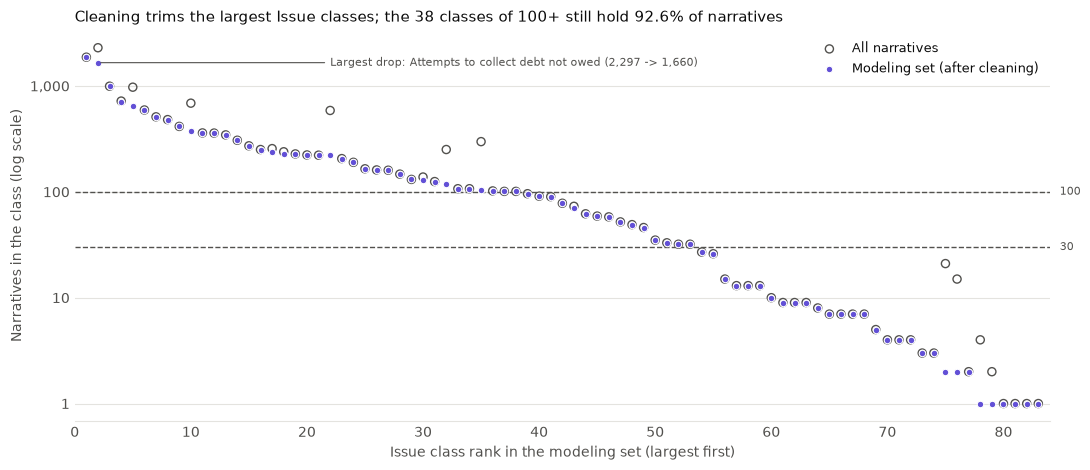

In [19]:
# --- Chart: Issue class sizes in the modeling set -----------------------------
# Same thresholds as the Target Candidates chart; "before" = all narratives, "after" = df_clean.
issue_before = class_sizes["Issue"]  # counted in the Target Candidates class-size chart
issue_after = df_clean["Issue"].value_counts()
issue_after = issue_after[issue_after > 0]  # a category column also lists empty categories

issue_sizes = (pd.DataFrame({"before": issue_before, "after": issue_after}).fillna(0).astype(int)
               .sort_values(["after", "before"], ascending=False))
issue_sizes["dropped"] = issue_sizes["before"] - issue_sizes["after"]
issue_sizes["dropped_%"] = (100 * issue_sizes["dropped"] / issue_sizes["before"]).round(1)

results = [
    check("after adds up to the modeling set", issue_after.sum() == len(df_clean),
          f"(expected {len(df_clean):,}, actual {issue_after.sum():,})"),
    check("no class grows", (issue_sizes["dropped"] >= 0).all(), f"(min dropped: {issue_sizes['dropped'].min()})"),
    check("no class disappears", (issue_sizes["after"] > 0).all(), f"({len(issue_after)} of {len(issue_before)} classes left)"),
]
assert all(results), "A chart check failed; see the FAIL lines above"


# band_summary() is defined in the Target Candidates class-size chart
issue_bands = pd.DataFrame([band_summary(issue_before), band_summary(issue_after)], index=["all narratives", "modeling set"])
display(issue_bands)

# Classes that lost the most narratives
print("Largest drops:")
display(issue_sizes.sort_values("dropped", ascending=False).head(5))

# The rare classes: how many lost any narratives
rare = issue_sizes[issue_sizes["after"] < MIN_CLASS_SMALL]
lost = rare[rare["dropped"] > 0]
print(f"Classes under {MIN_CLASS_SMALL} in the modeling set: {len(rare)} "
      f"({rare['after'].sum():,} narratives, {rare['before'].sum():,} before)")
print(f"Lost any narratives: {len(lost)} of {len(rare)}")
for issue, before, after in zip(lost.index, lost["before"], lost["after"]):
    print(f"  {issue}: {before} -> {after}")

# Plot: modeling-set count per class (violet), with the all-narratives count as a hollow gray ring
rank = np.arange(1, len(issue_sizes) + 1)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.scatter(rank, issue_sizes["before"], s=34, facecolor="none", edgecolor=INK_MUTED, linewidth=1, zorder=2,
           label="All narratives")
ax.scatter(rank, issue_sizes["after"], s=22, color=CLASS_COLOR, edgecolor="white", linewidth=0.8, zorder=3,
           label="Modeling set (after cleaning)")
for threshold in [MIN_CLASS_SMALL, MIN_CLASS_LARGE]:
    ax.axhline(threshold, color=INK_MUTED, lw=1, ls="--", zorder=1)
    ax.text(len(issue_sizes) + 1.5, threshold, f" {threshold}", va="center", ha="left", fontsize=8, color=INK_MUTED)

top_drop = issue_sizes["dropped"].idxmax()
r = issue_sizes.index.get_loc(top_drop) + 1
ax.annotate(f"Largest drop: {top_drop} ({issue_sizes.loc[top_drop, 'before']:,} -> {issue_sizes.loc[top_drop, 'after']:,})",
            (r, issue_sizes.loc[top_drop, "after"]), xytext=(22, issue_sizes.loc[top_drop, "after"]), textcoords="data",
            va="center", fontsize=8, color=INK_MUTED, arrowprops={"arrowstyle": "-", "color": INK_MUTED, "lw": 0.8})

ax.set_yscale("log")
ax.set_xlim(0, len(issue_sizes) + 1)
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Issue class rank in the modeling set (largest first)", color=INK_MUTED)
ax.set_ylabel("Narratives in the class (log scale)", color=INK_MUTED)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(which="both", colors=INK_MUTED, length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(frameon=False, loc="upper right", fontsize=9, labelcolor=INK)
ax.set_title(f"Cleaning trims the largest Issue classes; the {issue_bands.loc['modeling set', 'classes >=100']} classes "
             f"of 100+ still hold {issue_bands.loc['modeling set', '% >=100']}% of narratives", loc="left", fontsize=11, color=INK)
fig.tight_layout()
plt.show()

**Reading the chart**

- **One column per Issue class**, ranked by its size in the modeling set (largest on the left), on the same log scale as the Target Candidates chart.
- **Violet dot:** narratives in the modeling set. **Gray ring:** all narratives, before cleaning. Where the ring sits above the dot, that class lost copies; where they overlap, it lost none.
- **Dashed lines** at 30 and 100 narratives, the same scoring thresholds as before.

**What it shows** (from the tables above the chart)

1. **The bands did not change:** 38 classes still have 100+ narratives (13,656, 92.6% of the modeling set), 15 have 30-99 (884, 6.0%), and 30 have under 30 (215, 1.5%).
2. **The drops sit in a few large classes.** In debt collection, duplicates: *Attempts to collect debt not owed* lost 637 (27.7%, including the 322 template complaints), *Written notification about debt* 322 (33.1%), and *Took or threatened to take negative or legal action* 315 (45.8%). In credit reporting, duplicates plus mostly the off-menu rows: *Incorrect information on your report* lost 366 (62.4%), *Problem with a company's investigation into an existing problem* 194 (65.1%) and *Improper use of your report* 132 (52.6%).
3. **The tail is mostly untouched.** The 30 classes under 30 narratives held 251 narratives before cleaning and 215 after; 26 of them lost none. Two credit-reporting classes shrink sharply because most of their narratives were off-menu: *Credit monitoring or identity theft protection services* (21 to 2) and *Problem with fraud alerts or security freezes* (15 to 2).

**The decision holds:** after cleaning, no Issue drops out and no class falls into a lower size band, so all 83 stay as classes. Rare classes are examined in the sub-group evaluation, after the overall results.

### Cleaned Data Dictionary

One row per column of `df_clean`, the modeling set. `role` comes from `COLUMN_ROLES` in Clean; `dtype`, `null_%` and `n_unique` are read off `df_clean`; `cleaning_applied` says what Clean did to the column. Row-level rules (narratives only, duplicates) are in the row funnel under Clean.

In [20]:
# --- Cleaned data dictionary -------------------------------------------------
# What Clean did to each kept column
CLEANING_APPLIED = {
    "Complaint ID": "None; unique key",
    "Consumer complaint narrative": "None; the text is unchanged.",
    "Issue": "Copies of one text that disagreed: majority Issue kept, ties dropped; to category",
    "Product": "To category",
    "Sub-product": "To category; 'I do not know' kept as its own value",
    "Company": "To category",
    "State": "To category",
    "Date received": "Text (YYYY-MM-DD) to datetime",
    "Older American": "Yes/no flag split out of Tags",
    "Servicemember": "Yes/no flag split out of Tags",
}
assert list(CLEANING_APPLIED) == list(df_clean.columns), "Dictionary doesn't match df_clean's columns (names or order)"

clean_dict = pd.DataFrame({
    "role": pd.Series(COLUMN_ROLES),
    "dtype": df_clean.dtypes.astype(str),
    "null_%": (100 * df_clean.isna().mean()).round(1),
    "n_unique": df_clean.nunique(),
    "cleaning_applied": pd.Series(CLEANING_APPLIED),
})
clean_dict.index.name = "column"

with pd.option_context("display.max_colwidth", 120):
    display(clean_dict)

,role,dtype,null_%,n_unique,cleaning_applied
column,,,,,
Complaint ID,id,str,0.0,14755,None; unique key
Consumer complaint narrative,input,str,0.0,14755,None; the text is unchanged.
Issue,target,category,0.0,83,"Copies of one text that disagreed: majority Issue kept, ties dropped; to category"
Product,context,category,0.0,11,To category
Sub-product,context,category,0.0,52,To category; 'I do not know' kept as its own value
Company,subgroup,category,0.0,991,To category
State,subgroup,category,0.7,57,To category
Date received,subgroup,datetime64[us],0.0,30,Text (YYYY-MM-DD) to datetime
Older American,subgroup,bool,0.0,2,Yes/no flag split out of Tags


### Export

Saves the modeling set and its dictionary, after checking every column's type:
- `df_clean` goes to `data/processed/ccdb_modeling_set_june_2026.csv` (committed for grading; it is the one file in `data/processed/` that `.gitignore` lets through, besides the split). A CSV stores text only; Modeling reads it back and re-applies the types listed in the dictionary.
- The Cleaned Data Dictionary goes into the project `README.md`, between the `DATA DICTIONARY` markers.

In [21]:
# --- Export: schema check, CSV, README dictionary ----------------------------
PROCESSED_PATH = PROJECT_DIR / "data" / "processed" / "ccdb_modeling_set_june_2026.csv"
README_PATH = PROJECT_DIR / "README.md"
START, END = "<!-- DATA DICTIONARY START -->", "<!-- DATA DICTIONARY END -->"

# 1. Schema: every column has the type the models expect
EXPECTED_DTYPES = {
    "Complaint ID": "str", "Consumer complaint narrative": "str",
    "Issue": "category", "Product": "category", "Sub-product": "category", "Company": "category", "State": "category",
    "Date received": "datetime64[us]", "Older American": "bool", "Servicemember": "bool",
}
actual_dtypes = df_clean.dtypes.astype(str).to_dict()
wrong = {c: actual_dtypes.get(c) for c, t in EXPECTED_DTYPES.items() if actual_dtypes.get(c) != t}
assert check("every column has its expected type", not wrong and list(actual_dtypes) == list(EXPECTED_DTYPES),
             f"(mismatches: {wrong or 'none'})"), "Schema check failed; do not export"

# 2. CSV (read back and checked at the start of Modeling)
df_clean.to_csv(PROCESSED_PATH, index=False, encoding="utf-8")


# 3. README: replace the text between the markers with the dictionary as a Markdown table
def md_cell(value):
    """A table cell's text, with any | escaped so it doesn't split the cell."""
    return str(value).replace("|", r"\|")


header = ["column"] + list(clean_dict.columns)
table = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
table += ["| " + " | ".join(md_cell(v) for v in [col, *row]) + " |" for col, row in clean_dict.iterrows()]
block = "\n".join([
    f"Processed file: `data/processed/{PROCESSED_PATH.name}`, {len(df_clean):,} rows x {df_clean.shape[1]} columns "
    "(the modeling set built by `clean_ccdb()`). Types are not stored in a CSV; re-apply the `dtype` column when reading it.",
    "",
    *table,
])

readme = README_PATH.read_text(encoding="utf-8")
assert readme.count(START) == 1 and readme.count(END) == 1, "README markers missing or repeated"
before, rest = readme.split(START)
_, after = rest.split(END)
README_PATH.write_text(f"{before}{START}\n{block}\n{END}{after}", encoding="utf-8")

written = README_PATH.read_text(encoding="utf-8")
assert check("README dictionary written", all(f"| {c} |" in written for c in clean_dict.index),
             f"({len(clean_dict)} columns between the markers)"), "README check failed"
print(f"\nSaved {PROCESSED_PATH.relative_to(PROJECT_DIR).as_posix()} ({PROCESSED_PATH.stat().st_size / 1e6:.1f} MB) "
      f"and updated {README_PATH.relative_to(PROJECT_DIR).as_posix()}")

PASS  every column has its expected type  (mismatches: none)
PASS  README dictionary written  (10 columns between the markers)

Saved data/processed/ccdb_modeling_set_june_2026.csv (24.6 MB) and updated README.md


## Modeling

Both models start from the saved modeling set. The first cell reads the CSV back, re-applies the types from the Cleaned Data Dictionary, and checks that the result matches `df_clean`.

In [22]:
# --- Load the modeling set ----------------------------------------------------
# Only empty cells count as missing, so text such as "NA" in a narrative stays text
df_model = pd.read_csv(PROCESSED_PATH, dtype=str, keep_default_na=False, na_values=[""])
df_model["Date received"] = pd.to_datetime(df_model["Date received"], format="%Y-%m-%d")
for col in ["Older American", "Servicemember"]:
    df_model[col] = df_model[col].map({"True": True, "False": False}).astype(bool)
df_model[CATEGORY_COLS] = df_model[CATEGORY_COLS].astype("category")

model_dtypes = df_model.dtypes.astype(str).to_dict()
type_mismatches = {c: t for c, t in model_dtypes.items() if EXPECTED_DTYPES.get(c) != t}
results = [
    check("row and column count match df_clean", df_model.shape == df_clean.shape,
          f"(expected {df_clean.shape}, actual {df_model.shape})"),
    check("every column has its expected type", not type_mismatches, f"(mismatches: {type_mismatches or 'none'})"),
    check("narratives identical to df_clean",
          (df_model["Consumer complaint narrative"].values == df_clean["Consumer complaint narrative"].values).all()),
    check("Issue labels identical to df_clean",
          (df_model["Issue"].astype(str).values == df_clean["Issue"].astype(str).values).all()),
    check("missing State values match df_clean", df_model["State"].isna().sum() == df_clean["State"].isna().sum(),
          f"(expected {df_clean['State'].isna().sum()}, actual {df_model['State'].isna().sum()})"),
]
assert all(results), "A load check failed; see the FAIL lines above"
print(f"\nModeling set loaded: {len(df_model):,} narratives, {df_model['Issue'].nunique()} Issue classes")

PASS  row and column count match df_clean  (expected (14755, 10), actual (14755, 10))
PASS  every column has its expected type  (mismatches: none)
PASS  narratives identical to df_clean  
PASS  Issue labels identical to df_clean  
PASS  missing State values match df_clean  (expected 108, actual 108)

Modeling set loaded: 14,755 narratives, 83 Issue classes


#### Train / Test Split

One split, used by both models: 80% train, 20% test, stratified on Issue so each class keeps its share in both parts, with `SEED` for repeatability. The LLM labels the test set only; the baseline classifier learns from train and is scored on the same test set, so the two are compared on identical narratives.

Stratifying needs at least two narratives per class, so the Issues with a single narrative go to train. The split is saved as `data/processed/split_ids.csv` (Complaint ID and split) and committed, so both partners use the same rows even with a different scikit-learn version.


In [23]:
# --- Train / test split -------------------------------------------------------
# Result: df_model["split"] = "train" / "test", saved to data/processed/split_ids.csv
TEST_SIZE = 0.20
SPLIT_PATH = PROJECT_DIR / "data" / "processed" / "split_ids.csv"

issue_counts = df_model["Issue"].value_counts()
issue_counts = issue_counts[issue_counts > 0]          # a category column also lists empty categories
single_issues = issue_counts.index[issue_counts == 1]  # can't be stratified: go to train
splittable = df_model[~df_model["Issue"].isin(single_issues)]

train_ids, test_ids = train_test_split(splittable["Complaint ID"], test_size=TEST_SIZE,
                                       stratify=splittable["Issue"].astype(str), random_state=SEED)
df_model["split"] = np.where(df_model["Complaint ID"].isin(test_ids), "test", "train")
df_model[["Complaint ID", "split"]].to_csv(SPLIT_PATH, index=False, encoding="utf-8")

is_test = df_model["split"].eq("test")
saved = pd.read_csv(SPLIT_PATH, dtype=str)
results = [
    check("train + test = modeling set", len(train_ids) + len(test_ids) + len(single_issues) == len(df_model),
          f"({(~is_test).sum():,} train + {is_test.sum():,} test = {len(df_model):,}; "
          f"{len(single_issues)} single-narrative Issues in train)"),
    check("no Complaint ID in both parts", not set(train_ids) & set(test_ids)),
    check("every test Issue is also in train",
          set(df_model.loc[is_test, "Issue"]) <= set(df_model.loc[~is_test, "Issue"])),
    check("saved file matches df_model", saved.equals(df_model[["Complaint ID", "split"]].astype(str)),
          f"({len(saved):,} rows)"),
]
assert all(results), "A split check failed; see the FAIL lines above"

# How many test narratives each Issue gets: the base for scoring it
test_counts = df_model.loc[is_test, "Issue"].value_counts().reindex(issue_counts.index, fill_value=0)
bands = pd.cut(test_counts, bins=[-1, 0, 4, 19, np.inf], labels=["0", "1-4", "5-19", "20+"])
print("\nIssues by number of test narratives:")
print(bands.value_counts().sort_index().to_string(header=False))
print("\nIssues with no test narratives (all their narratives are in train):")
for issue in test_counts.index[test_counts == 0]:
    print(f"  {issue} ({issue_counts[issue]} total)")


PASS  train + test = modeling set  (11,805 train + 2,950 test = 14,755; 6 single-narrative Issues in train)
PASS  no Complaint ID in both parts  
PASS  every test Issue is also in train  
PASS  saved file matches df_model  (14,755 rows)

Issues by number of test narratives:
0        9
1-4     19
5-19    17
20+     38

Issues with no test narratives (all their narratives are in train):
  Credit monitoring or identity theft protection services (2 total)
  Problem with fraud alerts or security freezes (2 total)
  Vehicle was damaged or destroyed the vehicle (2 total)
  Identity theft protection or other monitoring services (1 total)
  Overdraft, savings, or rewards features (1 total)
  Problem with a company's investigation into an existing issue (1 total)
  Unable to get your credit report or credit score (1 total)
  Unexpected fees (1 total)
  Was approved for a loan, but didn't receive money (1 total)


#### The LLM's Options: Issue Menus from the Complaint Form

The LLM picks each narrative's Issue from the menu the form offers for its Product and Sub-product: `printed_menus`, read from the form in *Issues vs. the Complaint Form*. The form prints 29 Issue lists, and several sub-products share each one (all 11 debt collection sub-products get the same list), which gives the 55 menus counted there. Three lists repeat word for word elsewhere in the form, so 26 are distinct. Each is shown once below, with the sub-products that use it and how many test narratives the LLM labels with it.


In [24]:
# --- The LLM's options: every distinct Issue menu ---------------------------
# Sub-products whose menus are identical (same Issues, same order) are listed together
menu_groups = defaultdict(list)
for (product, sub_product), menu in printed_menus.items():
    menu_groups[(product, tuple(menu))].append(sub_product)

test_pairs = df_model.loc[df_model["split"].eq("test"), ["Product", "Sub-product"]].astype(str)
test_per_pair = test_pairs.value_counts()

results = [
    check("every menu in exactly one group", sum(len(subs) for subs in menu_groups.values()) == len(printed_menus),
          f"({len(printed_menus)} menus in {len(menu_groups)} distinct groups)"),
    check("every test narrative has a menu", set(test_per_pair.index) <= set(printed_menus),
          f"({len(test_per_pair)} Product / Sub-product pairs in test)"),
]
assert all(results), "A menu check failed; see the FAIL lines above"

for product in dict.fromkeys(p for p, _ in menu_groups):   # products in form order
    print(f"\n=== {product}")
    for (p, issues), subs in menu_groups.items():
        if p != product:
            continue
        n_test = sum(test_per_pair.get((product, s), 0) for s in subs)
        print(f"\n  Sub-products: {', '.join(subs)}")
        print(f"  {len(issues)} options | {n_test:,} test narratives")
        for issue in issues:
            print(f"    - {issue}")


PASS  every menu in exactly one group  (55 menus in 26 distinct groups)
PASS  every test narrative has a menu  (49 Product / Sub-product pairs in test)

=== Checking or savings account

  Sub-products: CD (Certificate of Deposit)
  3 options | 8 test narratives
    - Opening an account
    - Managing an account
    - Closing an account

  Sub-products: Checking account, Other banking product or service, Savings account
  5 options | 642 test narratives
    - Opening an account
    - Managing an account
    - Closing an account
    - Problem caused by your funds being low
    - Problem with a lender or other company charging your account

=== Credit card

  Sub-products: General-purpose credit card or charge card, Store credit card
  9 options | 522 test narratives
    - Getting a credit card
    - Advertising and marketing, including promotional offers
    - Trouble using your card
    - Fees or interest
    - Problem with a purchase shown on your statement
    - Problem when making pa

#### The LLM Labeler

The labeler is the v2 prompt from Assignment 7, unchanged; v2 scored best there. For each narrative the LLM gets its Product, Sub-product, the Issue menu the form offers for that pair (with the form's short descriptions) and the narrative, and returns a JSON record: 1-3 evidence quotes, its reasoning, the Issue and a confidence from 0 to 1. The output schema limits the Issue to that narrative's menu, so every answer is a valid option.

| Setting | Value |
|---|---|
| Model | `claude-sonnet-5-5` |
| Effort | `medium` |
| Max tokens | 16,000 (room for thinking plus the JSON record) |

This cell only builds the requests; nothing is sent. The batch cell below sends them.

In [25]:
# --- The LLM labeler: prompt and request (nothing is sent here) ----------------
# The v2 prompt from Assignment 7, word for word; build_request() turns one narrative into one API request
LABELER_MODEL = "claude-sonnet-5-5"
LABELER_MAX_TOKENS = 16_000   # room for the model's thinking plus the JSON record
LABELER_EFFORT = "medium"

V2_SYSTEM = """You label consumer complaints filed with the Consumer Financial Protection Bureau (CFPB). When filing, a consumer picks the issue that best describes their problem from a fixed list for their product. From the narrative alone, pick the issue the consumer most likely chose.

Rules:
- Choose the issue that matches the consumer's main problem, meaning what they want fixed, not every problem they mention.
- Use the issue descriptions to tell similar issues apart.
- Evidence: 1-3 short quotes copied exactly from the narrative.
- Reasoning: 2-3 sentences linking the evidence to the issue, including why the closest alternative fits less well.
- Confidence: the probability (0 to 1) that your issue is the one the consumer picked. Lower it when the narrative is vague or two issues fit.
- Personal details in narratives are masked as XXXX. Ignore them."""

USER_TEMPLATE = """Product: {product}
Sub-product: {sub_product}

Which issue does this complaint describe? Choose one of the issues the complaint form offers for this sub-product:
{menu}

Complaint narrative:
{narrative}

Give short quotes from the narrative as evidence, your reasoning, the issue, and your confidence from 0 to 1."""


def format_menu(menu):
    """The menu as a bulleted list, with the form's descriptions where it has them."""
    return "\n".join(f"- {issue}: {text}" if text else f"- {issue}" for issue, text in menu.items())


def output_schema(menu):
    """The JSON record the labeler returns; issue is limited to the complaint's menu."""
    return {
        "type": "object",
        "properties": {
            "evidence": {"type": "array", "items": {"type": "string"}},
            "reasoning": {"type": "string"},
            "issue": {"type": "string", "enum": list(menu)},
            "confidence": {"type": "number"},
        },
        "required": ["evidence", "reasoning", "issue", "confidence"],
        "additionalProperties": False,
    }


def build_request(row, model=LABELER_MODEL, thinking_display=None):
    """The exact API request for one narrative (a df_model row), for the given model.
    thinking_display="summarized" also returns a readable summary of the model's thinking (no extra cost)."""
    product, sub_product = str(row["Product"]), str(row["Sub-product"])
    menu = printed_menus[(product, sub_product)]
    user = USER_TEMPLATE.format(product=product, sub_product=sub_product,
                                menu=format_menu(menu), narrative=row[NARRATIVE_COL])
    request = {
        "model": model,
        "max_tokens": LABELER_MAX_TOKENS,
        "system": V2_SYSTEM,
        "messages": [{"role": "user", "content": user}],
        "output_config": {"effort": LABELER_EFFORT,
                          "format": {"type": "json_schema", "schema": output_schema(menu)}},
    }
    if thinking_display:
        request["thinking"] = {"type": "adaptive", "display": thinking_display}
    return request


# Free checks on every test narrative: a request builds, and the true Issue is one of its allowed answers
df_test = df_model[df_model["split"].eq("test")]
test_requests = {cid: build_request(row) for cid, row in zip(df_test["Complaint ID"], df_test.to_dict("records"))}
allowed = {cid: r["output_config"]["format"]["schema"]["properties"]["issue"]["enum"] for cid, r in test_requests.items()}
true_issue_allowed = [str(issue) in allowed[cid] for cid, issue in zip(df_test["Complaint ID"], df_test["Issue"])]
first_row = df_test.iloc[0]
rebuilt_same = json.dumps(build_request(first_row), sort_keys=True) == json.dumps(test_requests[first_row["Complaint ID"]], sort_keys=True)

results = [
    check("a request builds for every test narrative", len(test_requests) == len(df_test),
          f"(expected {len(df_test):,}, actual {len(test_requests):,})"),
    check("every true Issue is an allowed answer", all(true_issue_allowed),
          f"({sum(true_issue_allowed):,} of {len(true_issue_allowed):,})"),
    check("building a request twice gives the same request", rebuilt_same),
]
assert all(results), "A labeler check failed; see the FAIL lines above"

menu_sizes = pd.Series([len(a) for a in allowed.values()])
print(f"\nOptions per test request: min {menu_sizes.min()}, median {menu_sizes.median():.0f}, max {menu_sizes.max()}")

# One filled-in prompt, from a train narrative, exactly as the LLM will read it
example_row = df_model[df_model["split"].eq("train")].sample(1, random_state=SEED).iloc[0]
example = build_request(example_row)
print(f"\nExample request (train narrative {example_row['Complaint ID']}, true Issue: {example_row['Issue']})")
print("\n--- system ---\n" + example["system"])
print("\n--- user ---\n" + example["messages"][0]["content"])


PASS  a request builds for every test narrative  (expected 2,950, actual 2,950)
PASS  every true Issue is an allowed answer  (2,950 of 2,950)
PASS  building a request twice gives the same request  

Options per test request: min 2, median 7, max 11

Example request (train narrative 23515783, true Issue: Took or threatened to take negative or legal action)

--- system ---
You label consumer complaints filed with the Consumer Financial Protection Bureau (CFPB). When filing, a consumer picks the issue that best describes their problem from a fixed list for their product. From the narrative alone, pick the issue the consumer most likely chose.

Rules:
- Choose the issue that matches the consumer's main problem, meaning what they want fixed, not every problem they mention.
- Use the issue descriptions to tell similar issues apart.
- Evidence: 1-3 short quotes copied exactly from the narrative.
- Reasoning: 2-3 sentences linking the evidence to the issue, including why the closest alternativ

### Running the Labeler in Batches

Requests go to the Message Batches API: one submission for many narratives, at half the price of single calls, with results usually back within an hour. `run_batch()` does the whole round trip and saves one record per narrative in `outputs/llm/<stage>.jsonl` (stages are named by model, e.g. `pilot_sonnet`), which is committed, so the notebook runs from saved records without an API key.

- **Nothing is sent unless the run cell's own switch is `True`** (`RUN_SONNET_PILOT`, `RUN_OPUS_PILOT`, ...) and `ANTHROPIC_API_KEY` is set. With the switch off, the cell shows what would be sent and an estimated cost, then reads the saved records. Each cell has its own switch, so turning one on never sends another.
- **No narrative is paid for twice.** A saved record is reused while its request is unchanged (a fingerprint of the exact request), and a submitted batch's ID is saved right away, so a re-run after an interruption collects that batch instead of sending a new one.
- **Failed requests are not saved**, so the next run resends only those. A refused or cut-off answer is saved with an empty output and counts as a miss.

The pilots run the same 20 train narratives through Sonnet 5.5 and Opus 5.5, to check the round trip and compare accuracy and cost before one model labels the test set.

In [26]:
# --- LLM batch runner: send requests as one batch, save one record per narrative ---
# Nothing is sent unless the calling cell passes send=True and an API key is set; saved records are reused
LLM_DIR = PROJECT_DIR / "outputs" / "llm"
# Dollars per million tokens at batch prices (half of the standard price)
BATCH_PRICE_PER_MTOK = {
    "claude-sonnet-5-5": {"input": 1.00, "output": 5.00},    # standard $2 / $10
    "claude-opus-5-5": {"input": 2.00, "output": 10.00},     # standard $4 / $20
}
A7_AVG_TOKENS = {"input": 1376, "output": 220}           # per call, from Assignment 7's 22 v2 records
POLL_SECONDS, MAX_WAIT_MINUTES = 60, 30


def request_hash(request):
    """Fingerprint of the exact request; a saved record is reused only while this matches."""
    return hashlib.sha256(json.dumps(request, sort_keys=True).encode("utf-8")).hexdigest()[:16]


def batch_cost(input_tokens, output_tokens, model=LABELER_MODEL):
    """Dollars at the model's batch prices."""
    price = BATCH_PRICE_PER_MTOK[model]
    return (input_tokens * price["input"] + output_tokens * price["output"]) / 1e6


def make_client():
    """An API client if ANTHROPIC_API_KEY is set (stray spaces or quotes from pasting removed), else None."""
    key = os.environ.get("ANTHROPIC_API_KEY", "").strip().strip("'\"").strip()
    return anthropic.Anthropic(api_key=key) if key else None


def load_records(stage, requests):
    """Saved records for this stage whose request is unchanged, keyed by Complaint ID."""
    path = LLM_DIR / f"{stage}.jsonl"
    saved = {}
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            record = json.loads(line)
            saved[record["complaint_id"]] = record   # a later line replaces an earlier one
    return {cid: rec for cid, rec in saved.items()
            if cid in requests and rec["request_hash"] == request_hash(requests[cid])}


def collect_batch(client, stage, pending, requests, max_wait_minutes=MAX_WAIT_MINUTES):
    """Wait for a submitted batch, then append its results to <stage>.jsonl. Returns True once collected."""
    batch_id = pending["batch_id"]
    for _ in range(max_wait_minutes * 60 // POLL_SECONDS + 1):
        batch = client.messages.batches.retrieve(batch_id)
        if batch.processing_status == "ended":
            break
        print(f"  {batch_id}: {batch.processing_status}, {batch.request_counts.processing} still processing")
        time.sleep(POLL_SECONDS)
    else:
        print(f"  Still processing after {max_wait_minutes} minutes; run this cell again later to collect")
        return False

    new_records, failed = [], Counter()
    for result in client.messages.batches.results(batch_id):
        cid = result.custom_id
        if result.result.type != "succeeded":
            failed[result.result.type] += 1   # errored / canceled / expired: not saved, so resent next run
            continue
        msg = result.result.message
        text = next((b.text for b in msg.content if b.type == "text"), None)
        output = None
        if msg.stop_reason == "end_turn" and text:
            try:
                output = json.loads(text)
            except json.JSONDecodeError:
                pass
        thinking = "\n\n".join(b.thinking for b in msg.content if b.type == "thinking" and b.thinking)
        new_records.append({
            "complaint_id": cid, "request_hash": request_hash(requests[cid]), "batch_id": batch_id,
            "message_id": msg.id,                          # the API's ID for this exact answer (audit trail)
            "ended_at": str(batch.ended_at),               # when the batch finished (the API gives no per-answer time)
            "model": msg.model, "stop_reason": msg.stop_reason,
            "input_tokens": msg.usage.input_tokens, "output_tokens": msg.usage.output_tokens,
            "usage": msg.usage.to_dict(),                  # full usage block: cache and service-tier fields too
            "raw_text": text, "output": output,
            "thinking": thinking,                          # readable summary when requested, else empty
        })
    with open(LLM_DIR / f"{stage}.jsonl", "a", encoding="utf-8") as f:
        for record in new_records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
    pending.update(status="collected", ended_at=str(batch.ended_at), saved=len(new_records), failed=dict(failed))
    (LLM_DIR / f"{stage}_batch.json").write_text(json.dumps(pending, indent=1), encoding="utf-8")
    print(f"  Collected {batch_id}: {len(new_records)} saved, failed: {dict(failed) or 'none'}")
    return True


def run_batch(stage, rows, model=LABELER_MODEL, send=False, thinking_display=None, max_wait_minutes=MAX_WAIT_MINUTES):
    """Label rows (df_model rows) with the model through one batch; nothing is sent unless send is True.
    Returns the saved records for these rows as a DataFrame."""
    LLM_DIR.mkdir(parents=True, exist_ok=True)
    requests = {str(cid): build_request(row, model, thinking_display)
                for cid, row in zip(rows["Complaint ID"], rows.to_dict("records"))}
    pending_path = LLM_DIR / f"{stage}_batch.json"
    pending = json.loads(pending_path.read_text(encoding="utf-8")) if pending_path.exists() else None
    saved = load_records(stage, requests)   # read the saved file once
    todo = [cid for cid in requests if cid not in saved]
    client = make_client()
    print(f"Stage '{stage}': {len(requests):,} narratives, {len(requests) - len(todo):,} already saved, "
          f"{len(todo):,} to send | model: {model} | API key set: {client is not None} | send: {send}")

    if pending and pending["status"] == "submitted":
        # A batch was sent earlier and not yet collected: collect it, never send a second one
        print(f"Batch {pending['batch_id']} was submitted earlier ({pending['submitted']} requests)")
        if client is None:
            print("  Set ANTHROPIC_API_KEY to collect it")
        else:
            collect_batch(client, stage, pending, requests, max_wait_minutes)
    elif todo and send and client is not None:
        batch = client.messages.batches.create(
            requests=[{"custom_id": cid, "params": requests[cid]} for cid in todo])
        pending = {"batch_id": batch.id, "submitted": len(todo), "created_at": str(batch.created_at),
                   "status": "submitted"}
        pending_path.write_text(json.dumps(pending, indent=1), encoding="utf-8")   # saved before waiting
        print(f"Submitted batch {batch.id} with {len(todo):,} requests")
        collect_batch(client, stage, pending, requests, max_wait_minutes)
    elif todo:
        estimate = batch_cost(len(todo) * A7_AVG_TOKENS["input"], len(todo) * A7_AVG_TOKENS["output"], model)
        print(f"Nothing sent. Sending {len(todo):,} requests would cost about ${estimate:.2f} at batch prices "
              f"(Assignment 7's average tokens); set this cell's switch to True to send")

    records = load_records(stage, requests)
    if records:
        n_in = sum(r["input_tokens"] for r in records.values())
        n_out = sum(r["output_tokens"] for r in records.values())
        print(f"Saved records: {len(records):,} of {len(requests):,} | tokens in {n_in:,}, out {n_out:,} | "
              f"cost ${batch_cost(n_in, n_out, model):.2f} at batch prices")
    return pd.DataFrame([{
        "Complaint ID": cid, "predicted": (r["output"] or {}).get("issue"),
        "confidence": (r["output"] or {}).get("confidence"), "evidence": (r["output"] or {}).get("evidence"),
        "reasoning": (r["output"] or {}).get("reasoning"), "stop_reason": r["stop_reason"],
        "input_tokens": r["input_tokens"], "output_tokens": r["output_tokens"],
    } for cid, r in records.items()], columns=["Complaint ID", "predicted", "confidence", "evidence", "reasoning",
                                               "stop_reason", "input_tokens", "output_tokens"])


def show_pilot(results, rows, model):
    """Pilot answers next to the consumer's Issue, then the pilot cost projected to the test run."""
    if results.empty:
        print("No saved records yet")
        return
    view = results.merge(rows[["Complaint ID", "Product", "Issue"]].astype(str), on="Complaint ID")
    view["correct"] = view["predicted"] == view["Issue"]
    print(f"\n{model}: {view['correct'].sum()} of {len(view)} match the consumer's Issue "
          f"({len(view)} train narratives: a check of the round trip, not a score)")
    with pd.option_context("display.max_colwidth", 45):
        display(view[["Complaint ID", "Product", "Issue", "predicted", "confidence", "correct",
                      "stop_reason", "output_tokens"]])

    # Cost: measured on the pilot, then projected to the test run (same prompt, same batch prices)
    avg_in, avg_out = results["input_tokens"].mean(), results["output_tokens"].mean()
    per_narrative = batch_cost(avg_in, avg_out, model)
    n_test = int(df_model["split"].eq("test").sum())
    print(f"\nPilot cost: ${batch_cost(results['input_tokens'].sum(), results['output_tokens'].sum(), model):.4f} "
          f"for {len(results)} narratives at batch prices")
    print(f"Average per narrative: {avg_in:,.0f} input + {avg_out:,.0f} output tokens = ${per_narrative:.5f}")
    print(f"Projected test run: {n_test:,} narratives x ${per_narrative:.5f} = about ${n_test * per_narrative:.2f}")


def evaluate_pilot(results, rows):
    """How the pilot answers look: confidence when right vs. wrong, exact evidence, and the misses' reasoning."""
    if results.empty:
        return
    view = results.merge(rows[["Complaint ID", "Product", "Issue", NARRATIVE_COL]].astype(str), on="Complaint ID")
    view["correct"] = view["predicted"] == view["Issue"]
    # Evidence should be copied exactly from the narrative
    view["evidence_exact"] = [all(q in text for q in (quotes or [])) for quotes, text in zip(view["evidence"], view[NARRATIVE_COL])]

    print(f"\nCorrect: {view['correct'].sum()} of {len(view)}")
    print(f"Mean confidence: correct {view.loc[view['correct'], 'confidence'].mean():.2f}, "
          f"wrong {view.loc[~view['correct'], 'confidence'].mean():.2f}")
    print(f"All evidence quotes found word for word in the narrative: {view['evidence_exact'].sum()} of {len(view)}")

    # The misses: what the consumer picked, what the LLM picked, and why
    for _, row in view[~view["correct"]].iterrows():
        print(f"\n--- {row['Complaint ID']} | {row['Product']} | confidence {row['confidence']:.2f}")
        print(f"Consumer picked: {row['Issue']}")
        print(f"LLM picked:      {row['predicted']}")
        print(textwrap.fill("Reasoning: " + (row["reasoning"] or ""), width=110))


# Batch custom IDs allow letters, digits, _ and - (1-64 characters); Complaint IDs are digits
results = [
    check("every Complaint ID is a valid batch custom_id",
          df_model["Complaint ID"].astype(str).str.fullmatch(r"[A-Za-z0-9_-]{1,64}").all()),
    check("every model has a batch price", {LABELER_MODEL, "claude-opus-5-5"} <= set(BATCH_PRICE_PER_MTOK)),
]
assert all(results), "A batch-runner check failed; see the FAIL lines above"


PASS  every Complaint ID is a valid batch custom_id  
PASS  every model has a batch price  


In [27]:
# --- Pilot, Sonnet 5.5: 20 train narratives -------------------------------------
RUN_SONNET_PILOT = False   # True sends the narratives not saved yet (about $0.05 for 20)
PILOT_SIZE = 20
pilot_rows = df_model[df_model["split"].eq("train")].sample(PILOT_SIZE, random_state=SEED)
check("pilot narratives are all from train", pilot_rows["split"].eq("train").all(), f"({len(pilot_rows)} narratives)")

pilot_sonnet = run_batch("pilot_sonnet", pilot_rows, model=LABELER_MODEL, send=RUN_SONNET_PILOT)
show_pilot(pilot_sonnet, pilot_rows, LABELER_MODEL)
evaluate_pilot(pilot_sonnet, pilot_rows)


PASS  pilot narratives are all from train  (20 narratives)
Stage 'pilot_sonnet': 20 narratives, 20 already saved, 0 to send | model: claude-sonnet-5-5 | API key set: True | send: False
Saved records: 20 of 20 | tokens in 26,280, out 4,192 | cost $0.05 at batch prices

claude-sonnet-5-5: 14 of 20 match the consumer's Issue (20 train narratives: a check of the round trip, not a score)


,Complaint ID,Product,Issue,predicted,confidence,correct,stop_reason,output_tokens
0,23025445,Debt collection,Attempts to collect debt not owed,Attempts to collect debt not owed,0.96,True,end_turn,165
1,23565080,Debt collection,Attempts to collect debt not owed,Attempts to collect debt not owed,0.80,True,end_turn,221
2,23708750,Checking or savings account,Managing an account,Managing an account,0.88,True,end_turn,195
3,23065100,Checking or savings account,Closing an account,Closing an account,0.50,True,end_turn,235
4,23202237,Mortgage,Trouble during payment process,Trouble during payment process,0.82,True,end_turn,190
5,23654429,"Payday loan, title loan, personal loan, o...",Received a loan you didn't apply for,Received a loan you didn't apply for,0.35,True,end_turn,214
6,23496394,Checking or savings account,Managing an account,Problem with a lender or other company ch...,0.72,False,end_turn,289
7,23469354,Debt collection,Took or threatened to take negative or le...,Attempts to collect debt not owed,0.55,False,end_turn,189
8,23136344,Vehicle loan or lease,Managing the loan or lease,Managing the loan or lease,0.90,True,end_turn,247
9,23680512,"Payday loan, title loan, personal loan, o...",Problem with additional add-on products o...,Getting the loan,0.50,False,end_turn,200



Pilot cost: $0.0472 for 20 narratives at batch prices
Average per narrative: 1,314 input + 210 output tokens = $0.00236
Projected test run: 2,950 narratives x $0.00236 = about $6.97

Correct: 14 of 20
Mean confidence: correct 0.76, wrong 0.57
All evidence quotes found word for word in the narrative: 19 of 20

--- 23496394 | Checking or savings account | confidence 0.72
Consumer picked: Managing an account
LLM picked:      Problem with a lender or other company charging your account
Reasoning: The consumer paid a merchant via PayPal, funded from a checking account, and never received the
tickets. The bank and PayPal refused to dispute the charge, so the complaint is about a company charging the
account and not about low funds or account opening/closing. Managing an account is the closest alternative,
but the core issue is an unauthorized or unfulfilled charge from another company.

--- 23469354 | Debt collection | confidence 0.55
Consumer picked: Took or threatened to take negative or 

#### Pilot, Opus 5.5: the Same 20 Narratives

The same 20 narratives, prompt and settings, sent to `claude-opus-5-5`, which costs twice as much per token. Comparing the two outputs (matches, confidence, the misses' reasoning, projected test cost) decides which model labels the test set. With 20 narratives a difference of 2-3 matches can be chance, so the comparison is a preview, not a verdict.

In [28]:
# --- Pilot, Opus 5.5: the same 20 train narratives -------------------------------
OPUS_MODEL = "claude-opus-5-5"
RUN_OPUS_PILOT = False  # True sends the narratives not saved yet (about $0.10 for 20)

pilot_opus = run_batch("pilot_opus", pilot_rows, model=OPUS_MODEL, send=RUN_OPUS_PILOT)
show_pilot(pilot_opus, pilot_rows, OPUS_MODEL)
evaluate_pilot(pilot_opus, pilot_rows)


Stage 'pilot_opus': 20 narratives, 20 already saved, 0 to send | model: claude-opus-5-5 | API key set: True | send: False
Saved records: 20 of 20 | tokens in 26,280, out 5,826 | cost $0.11 at batch prices

claude-opus-5-5: 13 of 20 match the consumer's Issue (20 train narratives: a check of the round trip, not a score)


,Complaint ID,Product,Issue,predicted,confidence,correct,stop_reason,output_tokens
0,23565080,Debt collection,Attempts to collect debt not owed,Attempts to collect debt not owed,0.85,True,end_turn,228
1,23564969,Student loan,Dealing with your lender or servicer,Dealing with your lender or servicer,0.88,True,end_turn,210
2,23124469,Credit card,Problem with a purchase shown on your sta...,Problem with a purchase shown on your sta...,0.90,True,end_turn,270
3,23065100,Checking or savings account,Closing an account,Managing an account,0.45,False,end_turn,632
4,23264758,Debt collection,Attempts to collect debt not owed,Written notification about debt,0.42,False,end_turn,454
5,23314500,Checking or savings account,Managing an account,Managing an account,0.55,True,end_turn,382
6,22772427,Credit card,Getting a credit card,Getting a credit card,0.80,True,end_turn,186
7,22752337,Credit card,Problem with a purchase shown on your sta...,Problem with a purchase shown on your sta...,0.80,True,end_turn,221
8,23025445,Debt collection,Attempts to collect debt not owed,Attempts to collect debt not owed,0.93,True,end_turn,177
9,23304504,Credit card,Closing your account,Closing your account,0.45,True,end_turn,673



Pilot cost: $0.1108 for 20 narratives at batch prices
Average per narrative: 1,314 input + 291 output tokens = $0.00554
Projected test run: 2,950 narratives x $0.00554 = about $16.35

Correct: 13 of 20
Mean confidence: correct 0.75, wrong 0.54
All evidence quotes found word for word in the narrative: 19 of 20

--- 23065100 | Checking or savings account | confidence 0.45
Consumer picked: Closing an account
LLM picked:      Managing an account
Reasoning: Most of the complaint is about the bank's handling of transaction disputes (a hotel charge and a
double charge) and unexpected monthly maintenance fees. Both fit under managing the account. The refusal to
close the account matches 'Closing an account', but it comes last and plays a smaller role, so that issue is a
strong alternative rather than the main one.

--- 23264758 | Debt collection | confidence 0.42
Consumer picked: Attempts to collect debt not owed
LLM picked:      Written notification about debt
Reasoning: The core grievance i

**Decision: Sonnet 5.5 labels the test set.** On the same 20 narratives, Opus 5.5 matched the consumer's Issue 13 times and Sonnet 14. Opus also wrote longer answers (about 291 output tokens per narrative vs. 210), so at twice the price per token its test run would cost about \$16.35 against \$6.97 for Sonnet. With no gain in accuracy at more than twice the cost, Sonnet is the cost-effective choice. Twenty narratives cannot show a small difference either way, so this is a cost decision, not a claim that Sonnet is the more accurate model.

### Test Run: Sonnet 5.5 on the Test Set

The 2,950 test narratives go through the same prompt, model and settings as the Sonnet pilot, in one batch. One deliberate difference: the request asks for a readable summary of the model's thinking (`display: "summarized"`), kept for the governance review. The setting changes only what the API returns, not how the model thinks or what it costs.

Outputs, all committed:
- `outputs/llm/test_sonnet.jsonl`: one record per narrative, with the answer (evidence, reasoning, Issue, confidence), the thinking summary, the API's message ID, tokens and usage.
- `outputs/llm/test_sonnet_predictions.csv`: one row per narrative (true and predicted Issue, confidence, stop reason), rebuilt from the records on every run.

This cell only checks that the run worked. How good the answers are is the Evaluation section's job.

In [29]:
# --- Test run: Sonnet 5.5 on the 2,950 test narratives --------------------------
RUN_SONNET_TEST = False   # True sends the test narratives not saved yet (about $7, see the Sonnet pilot)
PREDICTIONS_PATH = LLM_DIR / "test_sonnet_predictions.csv"

test_sonnet = run_batch("test_sonnet", df_test, model=LABELER_MODEL, send=RUN_SONNET_TEST,
                        thinking_display="summarized", max_wait_minutes=60)

if len(test_sonnet):
    # One row per narrative, for evaluation and the governance review
    predictions = (df_test[["Complaint ID", "Product", "Sub-product", "Issue"]].astype(str)
                   .rename(columns={"Issue": "true_issue"})
                   .merge(test_sonnet[["Complaint ID", "predicted", "confidence", "stop_reason"]]
                          .rename(columns={"predicted": "predicted_issue"}), on="Complaint ID", how="left"))
    predictions.to_csv(PREDICTIONS_PATH, index=False, encoding="utf-8")

    # Run health: did every narrative come back with a usable answer, and what did it cost?
    batch_log = json.loads((LLM_DIR / "test_sonnet_batch.json").read_text(encoding="utf-8"))
    n_missing = predictions["stop_reason"].isna().sum()
    n_no_issue = test_sonnet["predicted"].isna().sum()
    pilot_projection = batch_cost(pilot_sonnet["input_tokens"].mean(), pilot_sonnet["output_tokens"].mean()) * len(df_test)
    actual = batch_cost(test_sonnet["input_tokens"].sum(), test_sonnet["output_tokens"].sum())

    print(f"\nSaved: {len(test_sonnet):,} of {len(df_test):,} | not saved: {n_missing:,} "
          f"(last batch failed: {batch_log.get('failed') or 'none'})")
    print("Stop reasons:", test_sonnet["stop_reason"].value_counts().to_dict())
    print(f"Answers without a parsed Issue: {n_no_issue:,}")
    print(f"Tokens: {test_sonnet['input_tokens'].sum():,} in, {test_sonnet['output_tokens'].sum():,} out")
    print(f"Cost: ${actual:.2f} actual vs. ${pilot_projection:.2f} projected from the Sonnet pilot")
    if batch_log.get("ended_at"):
        started, ended = pd.Timestamp(batch_log["created_at"]), pd.Timestamp(batch_log["ended_at"])
        print(f"Batch run time: {(ended - started).total_seconds() / 60:.1f} minutes (submitted {started:%H:%M}, finished {ended:%H:%M} UTC)")
    print(f"Predictions written to {PREDICTIONS_PATH.relative_to(PROJECT_DIR)} ({len(predictions):,} rows)")


Stage 'test_sonnet': 2,950 narratives, 2,950 already saved, 0 to send | model: claude-sonnet-5-5 | API key set: True | send: False
Saved records: 2,950 of 2,950 | tokens in 4,292,563, out 657,947 | cost $7.58 at batch prices

Saved: 2,950 of 2,950 | not saved: 0 (last batch failed: none)
Stop reasons: {'end_turn': 2950}
Answers without a parsed Issue: 0
Tokens: 4,292,563 in, 657,947 out
Cost: $7.58 actual vs. $6.97 projected from the Sonnet pilot
Batch run time: 4.3 minutes (submitted 23:36, finished 23:40 UTC)
Predictions written to outputs\llm\test_sonnet_predictions.csv (2,950 rows)


**Observations**
- **The run completed in full:** all 2,950 test narratives came back in one batch, none failed, every answer finished normally (`end_turn`), and every answer holds a valid Issue from its menu.
- **Faster than planned:** the batch took 4.3 minutes, well under the hour allowed.
- **Cost: \$7.58 vs. \$6.97 projected from the pilot** (about 9% over). Output per narrative matched the pilot (223 vs. 210 tokens); input was higher (1,455 vs. 1,314 tokens) because the pilot's 20 narratives happened to be shorter than the test set's average.
- **The thinking summary was not captured.** The request asked for it, but the field is empty for all 2,950 records. The likely reason is that at `medium` effort the model answered these prompts without a separate thinking step; output tokens barely changed from the pilot, which fits. Confirming it would take another paid call, so it was left there. Each record's own evidence and reasoning remain the explanation for its answer.

### Human Rating: Proof of Concept

Two raters, Alex and Tri, score the LLM's work on 20 test narratives: 10 the LLM got right and 10 it got wrong, shuffled so the order gives nothing away. For each narrative a rater first picks the Issue they think fits from its menu, then expands the LLM's answer (Issue, evidence, whether each quote is word for word, reasoning, confidence) and scores it on four dimensions from 0 to 4, with a written justification. The consumer's Issue is never shown; it sits in a separate answer key that the Evaluation section joins on.

- **Semi-blind picks.** The LLM's columns start collapsed, and raters pick before expanding them. Both raters still see the same LLM answer before scoring, so their agreement with the LLM, and with each other, reads as an upper bound.
- **Proof of concept.** 20 items show the design working end to end; validating the LLM for production would need 100+ fully blind items.

The rubric grades the LLM against the rules its own prompt gives it (main problem, exact evidence, closest alternative, calibrated confidence). **It is a draft until both raters agree on it** (`RUBRIC_FINAL`): until then the cell writes only `outputs/rating/rubric_draft.xlsx` for review. Once final, it writes the two rating sheets and the answer key, stamped with the rubric's fingerprint, and never overwrites a sheet that already exists.

In [ ]:
# --- Human rating: rubric, 20-item sample and rating sheets ---------------------
# Prints only counts and paths: no narrative, label or answer is shown here, so the raters stay blind
RUBRIC_FINAL = True   # True once Alex and Tri agree on the rubric: writes the rating sheets and the answer key
RATING_DIR = PROJECT_DIR / "outputs" / "rating"
RATERS = ["Alex", "Tri"]            # rater 1, rater 2
N_PER_GROUP = 10                    # hits and misses each

# Rubric (Alex's revision): each dimension grades one rule of the v2 prompt; anchors from 4 (best) to 0
RUBRIC = [
    {"dimension": "Issue choice",
     "question": "Does the LLM's Issue capture the consumer's main problem (what they wanted to fix)?",
     "anchors":
                {4: "The selected Issue is clearly the best match for the consumer's main problem.",
                 3: "The selected Issue captures the main problem about as well as another option.",
                 2: "The narrative partly supports the selected Issue. Another option better captures the main problem.",
                 1: "The selected Issue describes a secondary problem while missing the main problem.",
                 0: "The narrative provides no support for the selected Issue."}},
    {"dimension": "Evidence",
     "question": "Do the cited passages support the main problem and the selected Issue? Verbatim accuracy is checked separately in code.",
     "anchors": 
                {4: "The quotes directly support the main problem and the selected Issue.",
                 3: "At least one quote directly supports the main problem. There might be a minor gap or a weak quote.",
                 2: "The quote gives partial or indirect support and omits important details.",
                 1: "Quotes mostly concern background or secondary details. Little support for the main problem.",
                 0: "No quotes are supplied or quotes completely do not support the problem or Issue."}},
    {"dimension": "Reasoning",
     "question": "Does it link the evidence to the Issue and explain why the closest alternative fits less well?",
     "anchors": 
                {4: "A clear link between evidence and Issue. It names the closest alternative with solid reasoning.",
                 3: "A clear link. The alternative is named but thinly argued, or the alternative is missing from a clear case.",
                 2: "A generic link to evidence, or no alternative discussed when one clearly exists.",
                 1: "Vague or circular, or the argument partly contradicts the narrative.",
                 0: "Misreads the narrative, or contradicts its own choice."}},
    {"dimension": "Confidence",
     "question": "Does the stated confidence fit how clear the case is?",
     "anchors": 
                {4: "Confidence matches the clarity of the case: high when the case is clear, lower when two options fit.",
                 3: "Confidence is slightly high or low. It still reflects whether the case is clear or close.",
                 2: "Confidence noticeably overstates or understates how strongly the narrative favors the chosen Issue.",
                 1: "Confidence strongly overstates or understates certainty, e.g. very high confidence when two Issues fit equally.",
                 0: "Confidence directly conflicts with the LLM's own explanation."}},
]
RUBRIC_FINGERPRINT = hashlib.sha256(json.dumps(RUBRIC, sort_keys=True).encode("utf-8")).hexdigest()[:12]

rubric_table = pd.DataFrame([{"dimension": d["dimension"], "score": score, "anchor": text}
                             for d in RUBRIC for score, text in d["anchors"].items()])
print(f"Rubric: {'FINAL' if RUBRIC_FINAL else 'DRAFT'} | fingerprint {RUBRIC_FINGERPRINT}")
with pd.option_context("display.max_colwidth", 100):
    display(rubric_table.set_index(["dimension", "score"]))

# The 20 items: 10 hits and 10 misses from the test run, shuffled, numbered 1-20
test_records = {json.loads(line)["complaint_id"]: json.loads(line)
                for line in (LLM_DIR / "test_sonnet.jsonl").read_text(encoding="utf-8").splitlines()}
predictions = pd.read_csv(PREDICTIONS_PATH, dtype={"Complaint ID": str})
is_hit = predictions["predicted_issue"] == predictions["true_issue"]
rating_items = (pd.concat([predictions[is_hit].sample(N_PER_GROUP, random_state=SEED),
                           predictions[~is_hit].sample(N_PER_GROUP, random_state=SEED)])
                .sample(frac=1, random_state=SEED).reset_index(drop=True))
rating_items.insert(0, "item", range(1, len(rating_items) + 1))
rating_items = rating_items.merge(df_test[["Complaint ID", NARRATIVE_COL]].astype(str), on="Complaint ID")

results = [
    check("10 hits and 10 misses", (rating_items["predicted_issue"] == rating_items["true_issue"]).sum() == N_PER_GROUP
          and len(rating_items) == 2 * N_PER_GROUP, f"({len(rating_items)} items)"),
    check("every item has a saved LLM answer", rating_items["Complaint ID"].isin(test_records).all()),
    check("every rubric dimension has anchors 0-4", all(sorted(d["anchors"]) == [0, 1, 2, 3, 4] for d in RUBRIC)),
]
assert all(results), "A rating check failed; see the FAIL lines above"
print(f"Items span {rating_items['Product'].nunique()} products")

# ---- Excel helpers -------------------------------------------------------------------------
from openpyxl.cell.cell import ILLEGAL_CHARACTERS_RE
from openpyxl.styles import Alignment, Font
from openpyxl.worksheet.datavalidation import DataValidation

WRAP = Alignment(wrap_text=True, vertical="top")
BOLD = Font(bold=True)


def excel_text(value):
    """Text Excel accepts (control characters removed)."""
    return ILLEGAL_CHARACTERS_RE.sub("", str(value))


def add_rubric_sheet(wb, title="Rubric"):
    """The rubric as a readable table: one block per dimension."""
    ws = wb.create_sheet(title) if wb.worksheets[0].title != "Sheet" else wb.worksheets[0]
    ws.title = title
    ws.append(["Dimension", "Score", "Anchor"])
    for cell in ws[1]:
        cell.font = BOLD
    for d in RUBRIC:
        ws.append([d["dimension"], "", d["question"]])
        ws.cell(ws.max_row, 1).font = BOLD
        for score in sorted(d["anchors"], reverse=True):
            ws.append(["", score, d["anchors"][score]])
        ws.append([])
    ws.append([f"Rubric fingerprint: {RUBRIC_FINGERPRINT}"])
    for col, width in zip("ABC", (16, 8, 100)):
        ws.column_dimensions[col].width = width
    for row in ws.iter_rows():
        for cell in row:
            cell.alignment = WRAP
    return ws


RATING_COLUMNS = (["Item", "Product", "Sub-product", "Narrative", "Menu", "Your pick"]
                  + ["LLM Issue", "LLM evidence", "Quotes word for word", "LLM reasoning", "LLM confidence"]
                  + [f"{d['dimension']} (0-4)" for d in RUBRIC] + ["Justification", "Notes"])
INSTRUCTIONS = [
    "How to rate (work alone; do not open answer_key.xlsx):",
    "1. Read the narrative and its menu, then choose 'Your pick': the Issue you think fits best.",
    "2. Only then expand the LLM columns (the + above column G) to see the LLM's Issue, evidence, reasoning and confidence.",
    "3. Score the LLM's work on each dimension from 0 to 4 using the Rubric tab, and explain your scores under Justification.",
]


def verbatim_check(quotes, narrative):
    """'Yes' if every quote appears word for word in the narrative, else 'No' and the quotes that do not."""
    missing = [q for q in quotes if q not in narrative]
    return "Yes" if not missing else "No: " + "; ".join(f'"{q}"' for q in missing)


def write_rating_sheet(path, rater):
    """One rater's sheet: instructions, 20 rows, dropdowns, LLM columns collapsed; menus on a hidden tab."""
    wb = openpyxl.Workbook()
    ws = wb.active
    ws.title = "Rating"
    for line in INSTRUCTIONS:
        ws.append([line])
    ws.cell(1, 1).font = BOLD
    ws.append([f"Rater: {rater} | rubric fingerprint: {RUBRIC_FINGERPRINT}"])
    ws.append([])
    ws.append(RATING_COLUMNS)
    header_row = ws.max_row   # read after writing: a blank spacer row does not count toward max_row
    for cell in ws[header_row]:
        cell.font = BOLD
        cell.alignment = WRAP

    menus = wb.create_sheet("Menus")   # one column per item, feeding that row's pick dropdown
    score_dv = DataValidation(type="list", formula1='"0,1,2,3,4"', allow_blank=True)
    ws.add_data_validation(score_dv)
    for k, item in enumerate(rating_items.to_dict("records"), start=1):
        rec = test_records[item["Complaint ID"]]["output"]
        menu = list(printed_menus[(item["Product"], item["Sub-product"])])
        for r, issue in enumerate(menu, start=1):
            menus.cell(r, k, excel_text(issue))
        ws.append([item["item"], item["Product"], item["Sub-product"], excel_text(item[NARRATIVE_COL]),
                   "\n".join(f"- {issue}" for issue in menu), None,
                   rec["issue"], "\n".join(f'"{q}"' for q in rec["evidence"]),
                   verbatim_check(rec["evidence"], item[NARRATIVE_COL]), rec["reasoning"], rec["confidence"]]
                  + [None] * len(RUBRIC) + [None, None])
        row = ws.max_row   # the row just written
        col = openpyxl.utils.get_column_letter(k)
        pick_dv = DataValidation(type="list", formula1=f"=Menus!${col}$1:${col}${len(menu)}", allow_blank=True)
        ws.add_data_validation(pick_dv)
        pick_dv.add(ws.cell(row, 6))
        for j in range(len(RUBRIC)):
            score_dv.add(ws.cell(row, 12 + j))
        for cell in ws[row]:
            cell.alignment = WRAP
    menus.sheet_state = "hidden"

    widths = [6, 18, 18, 80, 40, 30, 30, 40, 22, 50, 10] + [12] * len(RUBRIC) + [50, 30]
    for j, width in enumerate(widths, start=1):
        ws.column_dimensions[openpyxl.utils.get_column_letter(j)].width = width
    ws.column_dimensions.group("G", "K", hidden=True, outline_level=1)   # LLM columns start collapsed
    ws.freeze_panes = ws.cell(header_row + 1, 2)
    add_rubric_sheet(wb)
    wb.save(path)


def write_answer_key(path):
    """Item -> Complaint ID, consumer's Issue, LLM's Issue and confidence, hit or miss."""
    key = rating_items[["item", "Complaint ID", "true_issue", "predicted_issue", "confidence"]].copy()
    key["hit"] = key["true_issue"] == key["predicted_issue"]
    key["rubric_fingerprint"] = RUBRIC_FINGERPRINT
    key.to_excel(path, index=False)


# ---- Write: the draft rubric for review, or the final sheets ----------------------------------
RATING_DIR.mkdir(parents=True, exist_ok=True)
if not RUBRIC_FINAL:
    draft = openpyxl.Workbook()
    add_rubric_sheet(draft)
    draft.save(RATING_DIR / "rubric_draft.xlsx")
    print(f"\nDraft rubric written to {(RATING_DIR / 'rubric_draft.xlsx').relative_to(PROJECT_DIR)} for review; "
          f"rating sheets are written once RUBRIC_FINAL = True")
else:
    targets = {RATING_DIR / f"rating_{name.lower()}.xlsx": (write_rating_sheet, name) for name in RATERS}
    targets[RATING_DIR / "answer_key.xlsx"] = (write_answer_key, None)
    for target, (writer, rater) in targets.items():
        if target.exists():
            print(f"Kept (already exists, never overwritten): {target.relative_to(PROJECT_DIR)}")
            continue
        writer(target, rater) if rater else writer(target)
        print(f"Written: {target.relative_to(PROJECT_DIR)}")


Rubric: FINAL | fingerprint 659112f0c72e


anchor
dimension    score                                                                                                     
Issue choice 4                            The selected Issue is clearly the best match for the consumer's main problem.
             3                            The selected Issue captures the main problem about as well as another option.
             2       The narrative partly supports the selected Issue. Another option better captures the main problem.
             1                         The selected Issue describes a secondary problem while missing the main problem.
             0                                                The narrative provides no support for the selected Issue.
Evidence     4                                     The quotes directly support the main problem and the selected Issue.
             3       At least one quote directly supports the main problem. There might be a minor gap or a weak quote.
             2                                 The quote gives partial or indirect support and omits important details.
             1              Quotes mostly concern background or secondary details. Little support for the main problem.
             0                         No quotes are supplied or quotes completely do not support the problem or Issue.
Reasoning    4          A clear link between evidence and Issue. It names the closest alternative with solid reasoning.
             3      A clear link. The alternative is named but thinly argued, or the alternative is missing from a c...
             2                         A generic link to evidence, or no alternative discussed when one clearly exists.
             1                                     Vague or circular, or the argument partly contradicts the narrative.
             0                                                   Misreads the narrative, or contradicts its own choice.
Confidence   4      Confidence matches the clarity of the case: high when the case is clear, lower when two options ...
             3                Confidence is slightly high or low. It still reflects whether the case is clear or close.
             2      Confidence noticeably overstates or understates how strongly the narrative favors the chosen Issue.
             1      Confidence strongly overstates or understates certainty, e.g. very high confidence when two Issu...
             0                                            Confidence directly conflicts with the LLM's own explanation.

PASS  10 hits and 10 misses  (20 items)
PASS  every item has a saved LLM answer  
PASS  every rubric dimension has anchors 0-4  
Items span 5 products
Written: outputs\rating\rating_alex.xlsx
Written: outputs\rating\rating_tri.xlsx
Written: outputs\rating\answer_key.xlsx
